# 19 · Anomali Tespiti (Anomaly Detection: Isolation Forest, LOF, One-Class SVM, Elliptic Envelope)

> **Bu notebook'ta ne öğreneceğiz?**
> Kümeleme (16-17) "verinin doğal gruplarını bul" diyordu; boyut indirgeme (18) "veriyi sıkıştır/görselleştir". Anomali tespiti ise tersini sorar:
> **"Hangi gözlem diğerlerine benzemiyor?"** Etiketli örnek neredeyse hiç yoktur (dolandırıcılık, arıza, saldırı **nadirdir** ve her yeni türü farklıdır),
> bu yüzden çoğu zaman **denetimsiz** (veya yalnızca "normal" verinin bilindiği **yarı-denetimli**) çalışırız. Dört klasik yöntem ailesini, her birini
> önce **küçük, elle hesaplanabilir bir örnekle**, sonra gerçek veriyle öğreneceğiz:
>
> 1. **Isolation Forest:** Anormal noktalar "az ve farklı" olduğu için rastgele bölmelerle **çok çabuk izole** edilir — ortalama yol uzunluğu kısa = şüpheli.
> 2. **Local Outlier Factor (LOF):** Bir noktanın yoğunluğunu **komşularının yoğunluğuyla** kıyaslar — *yerel* anomalileri yakalar (global yöntemlerin kaçırdığı).
> 3. **One-Class SVM:** Normal verinin etrafına **kernel ile esnek bir sınır** çizer; sınırın dışı anomali ($\nu$ parametresi ile kontrol).
> 4. **Elliptic Envelope (Robust Kovaryans / MCD):** Normal veri **çok değişkenli Gauss** varsayımıyla, aykırı değerlere dayanıklı bir **Mahalanobis** elipsi.
>
> Sonda hepsini aynı veri setlerinde **ROC-AUC, Average Precision, Precision@n** ile kıyaslayacak, bir **zaman serisi** anomalisi (NYC taksi talebi) üzerinde
> boru hattı kuracak ve "etiket varsa denetimli model ne kazandırır?" sorusunu cevaplayacağız.
>
> **Önkoşul:** 12 · Dengesiz Öğrenme (PR-AUC, eşik/maliyet), 05 · k-NN, 07 · SVM ve Kernel, 08-09 · Karar Ağaçları/Random Forest, 16-17 · Kümeleme (yoğunluk), 18 · Boyut İndirgeme (PCA görselleştirme).
>
> **Veri:** `Cardio` (ODDS/UCI Cardiotocography; 1.831 fetal kalp ritmi kaydı, 20 öznitelik — ODDS'daki 21'den, biri diğerlerinin tam doğrusal birleşimi çıktığı için atıldı (Adım 1); %9.6 patolojik = anomali), `Letter` (ODDS/UCI Letter Recognition'dan türetilmiş; 1.600 örnek,
> 32 öznitelik, %6.25 anomali), `Arrhythmia` (ODDS/UCI; 452 hasta, 274 öznitelik — *p, n'e yakın* zor durum) ve `NYC Taxi` (Numenta Anomaly Benchmark; 10.320 yarım-saatlik
> yolculuk sayısı, 5 gerçek olay). Hepsi serinin önceki notebook'larında **kullanılmamış** veri setleri; yöntemleri sezgisel göstermek için sentetik veriler de var.
>
> **Araçlar:** `sklearn.ensemble.IsolationForest`, `sklearn.neighbors.LocalOutlierFactor`, `sklearn.svm.OneClassSVM`, `sklearn.covariance` (`EllipticEnvelope`, `MinCovDet`),
> R (`isotree`, `dbscan::lof`, `robustbase`), DuckDB (SQL).

## 1 · Anomali Nedir? Üç Tür, Üç Kurulum

**Tanım:** Verinin büyük çoğunluğundan **anlamlı biçimde farklı** davranan gözlem. "Farklı"nın ne demek olduğu yönteme göre değişir: uzak, izole, düşük yoğunluklu, kovaryans yapısına aykırı...

| Tür | Tanım | Örnek |
|---|---|---|
| **Nokta (point) anomalisi** | Tek bir gözlem tüm veriye göre aykırı | 50.000 ₺'lik tek kredi kartı harcaması, normalde 200 ₺ harcayan müşteri |
| **Bağlamsal (contextual) anomali** | Gözlem *bağlamına* göre aykırı (zaman, konum) | Ocakta 30 °C sıcaklık; gece 3'te patlayan taksi talebi |
| **Kolektif (collective) anomali** | Tek tek normal, **birlikte** anormal bir dizi | Düşük ama süren bir ağ trafiği artışı (DDoS), EKG'de bozuk ritim dizisi |

**Üç öğrenme kurulumu:**

| Kurulum | Elde ne var? | Ne yaparız? | Sklearn terimi |
|---|---|---|---|
| **Denetimsiz** (outlier detection) | Etiketsiz karışık veri | Eğitim verisindeki aykırıları bul | `fit` + `predict` (aynı veri) |
| **Yarı-denetimli** (novelty detection) | **Sadece normal** veri | Yeni gelenin "normale benzeyip benzemediğini" söyle | `novelty=True` + `predict` (yeni veri) |
| **Denetimli** | Etiketli normal + anomali | Dengesiz sınıflandırma (12) | Sınıflandırıcılar |

**Endüstride nerede kullanılır?** Bankacılıkta kart dolandırıcılığı ve AML (kara para aklama) izleme; üretimde titreşim/sıcaklık sensörlerinden **kestirimci bakım**; siber güvenlikte
ağ saldırısı ve sızma tespiti; sağlıkta EKG/KTG'de anormal ritim; e-ticarette sahte yorum/sahte hesap; telekom ve bulut altyapısında KPI/metrik izleme (**AIOps**); enerjide sayaç hırsızlığı.
Savunma/havacılıkta uçuş verisinde (FDM) beklenmeyen davranış, sensör arızası tespiti de aynı araç kutusunu kullanır.

**Zorluk — "doğru cevap" yok:** Çoğu projede anomalinin tanımı **iş problemi**dir. Etiketleri (varsa) yalnızca **değerlendirme** için kullanırız, yöntem seçimi ve eşik her zaman iş maliyetiyle (kaçırılan dolandırıcılık vs yanlış alarm) birlikte düşünülür.

## 2 · Basit Çizgi: Z-skoru, IQR ve Mahalanobis

Gelişmiş yöntemlerin **neden gerektiğini** görmek için önce temel çizgiye bakalım.

- **Z-skoru (tek değişkenli):** $z_j=\dfrac{x_j-\mu_j}{\sigma_j}$; $|z|>3$ → anomali. Değişkenleri **tek tek** inceler, **birlikte** anormal olanı kaçırır.
- **IQR kuralı:** $x<Q_1-1.5\,\text{IQR}$ veya $x>Q_3+1.5\,\text{IQR}$ (boxplot bıyıkları). Çarpık dağılımlarda daha dayanıklı.
- **Mahalanobis uzaklığı (çok değişkenli):** $d_M^2(\mathbf{x})=(\mathbf{x}-\boldsymbol{\mu})^\top\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu})$ — değişkenler arası **korelasyonu** hesaba katan uzaklık.
  Gauss varsayımıyla $d_M^2\sim\chi^2_p$ olduğundan eşik $\chi^2_{p,\,0.975}$ gibi bir kantil olur.

### 2.1 🔍 Somut örnek: korelasyon uzaklığı değiştirir
$\boldsymbol{\mu}=(0,0)$, $\boldsymbol{\Sigma}=\begin{pmatrix}1&0.8\\0.8&1\end{pmatrix}$ ($\rho=0.8$; $\boldsymbol{\Sigma}^{-1}=\tfrac{1}{0.36}\begin{pmatrix}1&-0.8\\-0.8&1\end{pmatrix}$).
İki nokta: $A=(1,1)$ ve $B=(1,-1)$. İkisinin de orijine **Öklid uzaklığı aynı** ($\sqrt2$), ama:

$$d_M^2(A)=\tfrac{1}{0.36}(1-0.8-0.8+1)=1.11,\qquad d_M^2(B)=\tfrac{1}{0.36}(1+0.8+0.8+1)=10.0.$$

$\chi^2_{2,0.975}=7.38$ olduğundan **B anomali, A normal**: $A$ verinin "korelasyon yönü"nde (birlikte artış), $B$ ise bu yönün **tersinde** — aynı uzaklık, çok farklı olağanlık.
Adım 1'de kodla yeniden üreteceğiz. **Zayıflık:** $\boldsymbol{\mu},\boldsymbol{\Sigma}$ tahmini aykırı değerlerle **bozulur** ("maskeleme") → robust tahmin (MCD, §6).

## 3 · Isolation Forest: "Anormal Olan Çabuk İzole Edilir"

### 3.1 Sezgi
Normal gözlemleri tarif etmek yerine **anormali doğrudan izole etmeyi** dener (Liu, Ting, Zhou, 2008). Bir kalabalığın ortasındaki kişiyi odadan ayırmak için çok sayıda çizgi gerekir;
kalabalıktan uzakta duran kişi ise **birkaç rastgele çizgide** tek başına kalır. Rastgele bölmelerle izolasyon için gereken **ortalama adım sayısı** bir normallik ölçüsüdür.

### 3.2 Algoritma
1. $T$ ağaç kurulur; her ağaç eğitim verisinden $\psi$ büyüklüğünde **alt örneklem** ( `max_samples`, varsayılan 256) alır — alt örnekleme hem hızlandırır hem "maskeleme/batma" (swamping) etkisini azaltır.
2. Her düğümde **rastgele bir özellik** $q$ ve $[\min,\max]$ aralığından **rastgele bir kesme değeri** $p$ seçilir; veri $x_q<p$ ve $x_q\ge p$ diye ikiye ayrılır. Düğümde tek örnek kalana veya derinlik sınırına ($\lceil\log_2\psi\rceil$) ulaşana dek tekrar.
3. Bir $\mathbf{x}$'in **yol uzunluğu** $h(\mathbf{x})$ = köke uzaklığı (yaprakta $\ge2$ örnek kalmışsa $+c(\text{boyut})$ düzeltmesi). $E[h(\mathbf{x})]$ tüm ağaçlar üzerinden ortalama.
4. **Anomali skoru:** $\displaystyle s(\mathbf{x},\psi)=2^{-E[h(\mathbf{x})]/c(\psi)},\qquad c(n)=2H(n-1)-\frac{2(n-1)}{n},\ \ H(i)\approx\ln i+0.5772.$
   $c(n)$, $n$ örnekli bir ikili arama ağacında *başarısız aramanın* ortalama yol uzunluğudur — normalizasyon sabitidir.

### 3.3 🔍 Skor yorumu (elle)
$\psi=256$ için $c(256)=2(\ln255+0.5772)-2\cdot255/256=10.24$. Üç farklı ortalama yol uzunluğu için:

| $E[h(\mathbf{x})]$ | $s=2^{-E[h]/10.24}$ | Yorum |
|---|---|---|
| 2 | **0.873** | Çok çabuk izole edildi → güçlü anomali |
| 4 | 0.763 | Şüpheli |
| 10.24 ($=c$) | 0.500 | Tam ortalama davranış → ayırt edilemez |
| 12+ | $<0.45$ | Derin, kalabalığın içinde → normal |

Kural: $s\to1$ anomali, $s<0.5$ güvenle normal. Adım 2'de bunu sıfırdan yazdığımız ağaçlarla yeniden üreteceğiz.

### 3.4 Artı / eksi
**+** Doğrusal zaman ($O(T\psi\log\psi)$, $n$'e bağımlı değil), ölçekleme/mesafe gerekmez, yüksek boyutlu veriyle başa çıkar, **kategorik+sayısal** karışımda (kodlama sonrası) iyi bir ilk adaydır.
**−** Eksene paralel bölmeler → **çapraz** (korelasyonlu) anomalilerde "hayalet" bölgeler (Extended Isolation Forest bunu düzeltir); *yerel yoğunluk* farklarını görmez (LOF görür); gürültülü, ilgisiz öznitelikler skoru bulandırır.

## 4 · Local Outlier Factor (LOF): "Komşularına Göre Ne Kadar Seyrek?"

### 4.1 Sezgi
Bir şehirde 3 km'lik mesafe İstanbul'da "yakın", Bolu'da "uzak" sayılır — **uzaklığın anlamı yerel yoğunluğa bağlıdır**. Global bir eşik (Mahalanobis, k-NN uzaklığı) yoğunluğu değişen verilerde ya yoğun bölgedeki anomalileri kaçırır ya seyrek bölgedeki normalleri işaretler.
LOF (Breunig ve ark., 2000) bir noktanın yoğunluğunu **kendi komşularının yoğunluğuyla** kıyaslar.

### 4.2 Tanımlar ($k$ = `n_neighbors`)
- **$k$-uzaklık** $d_k(A)$: $A$'nın $k$. en yakın komşusuna uzaklık; $N_k(A)$: $k$-komşuluk.
- **Erişilebilirlik uzaklığı:** $\text{reach-dist}_k(A,B)=\max\{d_k(B),\ d(A,B)\}$ (yakın komşular için *gürültüyü yumuşatır*).
- **Yerel erişilebilirlik yoğunluğu:** $\text{lrd}_k(A)=\left(\dfrac{1}{|N_k(A)|}\sum_{B\in N_k(A)}\text{reach-dist}_k(A,B)\right)^{-1}$ (ortalama erişilebilirlik uzaklığının tersi = yoğunluk).
- **LOF:** $\displaystyle\text{LOF}_k(A)=\frac{1}{|N_k(A)|}\sum_{B\in N_k(A)}\frac{\text{lrd}_k(B)}{\text{lrd}_k(A)}$ — "komşularımın yoğunluğu / benim yoğunluğum".
  $\approx1$ → komşularla aynı yoğunluk (normal); $\gg1$ → komşularımdan **çok daha seyrek** (anomali).

### 4.3 🔍 Somut örnek: tek boyutta 4 nokta, $k=2$
Noktalar $\{1,2,3,10\}$. Komşular: $N(1)=\{2,3\}$, $N(2)=\{1,3\}$, $N(3)=\{2,1\}$, $N(10)=\{3,2\}$. $k$-uzaklıklar: $d_k(1)=2,\ d_k(2)=1,\ d_k(3)=2,\ d_k(10)=8$.

| Nokta | Erişilebilirlik uzaklıkları | Ortalama | lrd | LOF |
|---|---|---|---|---|
| 1 | $\max(1,1)=1,\ \max(2,2)=2$ | 1.5 | 0.667 | $\frac{(0.5+0.667)/2}{0.667}=\mathbf{0.875}$ |
| 2 | $\max(2,1)=2,\ \max(2,1)=2$ | 2.0 | 0.500 | $\frac{(0.667+0.667)/2}{0.5}=\mathbf{1.333}$ |
| 3 | $\max(1,1)=1,\ \max(2,2)=2$ | 1.5 | 0.667 | **0.875** |
| 10 | $\max(2,7)=7,\ \max(1,8)=8$ | 7.5 | 0.133 | $\frac{(0.667+0.5)/2}{0.133}=\mathbf{4.375}$ |

Nokta 10'un LOF'u **4.4** — komşularından ~4 kat seyrek; diğerleri $\approx1$. Adım 3'te sıfırdan LOF ile bu tabloyu ve `sklearn` sonucunu birebir yeniden üreteceğiz.

### 4.4 `novelty` ve $k$ seçimi
- `novelty=False` (varsayılan): sadece `fit_predict` / `negative_outlier_factor_` — eğitim verisindeki aykırılar (denetimsiz).
- `novelty=True`: **sadece normal veriyle** `fit`, yeni veride `predict/score_samples` — üretimde streaming skorlama.
- $k$ çok küçük → gürültüye duyarlı; çok büyük → yerel yapıyı kaybeder (global yönteme yaklaşır). Pratik başlangıç: $k\in[20,50]$; en az bir "anomali kümesi"nin büyüklüğü kadar.

## 5 · One-Class SVM: Normal Verinin Etrafına Kernel Sınırı

### 5.1 Fikir
SVM'in (07) tek sınıflı uyarlaması (Schölkopf ve ark., 2001): veriyi RBF kernel özellik uzayında **orijinden maksimum marjla ayıran** bir hiper-düzlem bul; orijine yakın taraf = anomali. Orijinal uzayda bu, **normal veriyi saran esnek bir kapalı sınırdır**.

$$\min_{\mathbf{w},\boldsymbol{\xi},\rho}\ \tfrac12\lVert\mathbf{w}\rVert^2+\tfrac{1}{\nu n}\sum_i\xi_i-\rho\quad\text{s.t.}\quad \mathbf{w}^\top\phi(\mathbf{x}_i)\ge\rho-\xi_i,\ \xi_i\ge0.$$

Karar fonksiyonu $f(\mathbf{x})=\sum_i\alpha_i k(\mathbf{x}_i,\mathbf{x})-\rho$; $f<0$ → anomali.

### 5.2 $\nu$ özelliği (pratikte çok işe yarar)
$\nu\in(0,1]$ iki şeyi **birden** sınırlar: **eğitim verisinin en çok $\nu$ oranı** sınırın dışında kalır ve **destek vektörü oranı en az $\nu$**'dur. Yani $\nu$, "beklenen anomali oranı"nın üst sınırı gibi okunabilir (yine de gerçek oran bilinmiyorsa dikkatli kullanılır).

### 5.3 Pratik notlar
- **Ölçekleme zorunludur** (kernel uzaklığa dayanır); `StandardScaler` şart.
- `gamma='scale'` ($=1/(p\,\text{Var}(X))$) makul başlangıç; çok büyük $\gamma$ → her nokta kendi adası (aşırı öğrenme), çok küçük → neredeyse doğrusal/çok kaba sınır.
- Eğitimi $O(n^2)$–$O(n^3)$: **>50-100 bin** satırda yavaştır → `SGDOneClassSVM` veya Isolation Forest.
- **Yarı-denetimli** kullanım en güçlüsüdür: sadece normallerle eğit, yeni veriyi skorla (aşağıda göreceğiz).

**Endüstride nerede kullanılır?** Fabrikada "sağlıklı" makine titreşim profili öğrenip sapmayı izleme; ağ saldırısı tespitinde normal trafik profili; görüntü/doküman sahtecilik tespitinde tek sınıf modelleme.

## 6 · Elliptic Envelope ve Robust Kovaryans (MCD)

### 6.1 Fikir
Normal verinin **çok değişkenli Gauss** olduğunu varsay; $\boldsymbol{\mu},\boldsymbol{\Sigma}$'yı **aykırı değerlerden etkilenmeyecek** biçimde tahmin et ve Mahalanobis uzaklığı eşiğini aşanları anomali say. Eşik: $d_M^2>\chi^2_{p,\,1-c}$ (`contamination` $c$ oranına göre).

### 6.2 Neden "robust"? Maskeleme (masking)
Klasik $\hat{\boldsymbol{\mu}},\hat{\boldsymbol{\Sigma}}$ aykırı değerleri de içeren **tüm** veriyle hesaplanır: aykırılar ortalamayı kendilerine çeker ve kovaryansı **şişirir** → kendi Mahalanobis uzaklıkları küçülür, **gizlenirler**.
**MCD (Minimum Covariance Determinant, Rousseeuw 1984/1999):** veriden, kovaryans determinantı **en küçük** olan $h$ gözlemlik alt kümeyi bulur (varsayılan $h\approx(n+p+1)/2$, kırılma noktası ~%50) ve $\boldsymbol{\mu},\boldsymbol{\Sigma}$'yı bu "temiz çekirdekten" tahmin eder. `FastMCD` algoritması ile pratik hızda hesaplanır.

### 6.3 Sınırlar
- **Gauss ve tek mod** varsayımı: çok modlu/çarpık dağılımlarda yanlış alarm üretir.
- $p$ büyükse ($p\gtrsim n/2$) MCD kararsız/tekil hale gelir — Adım 5'te Arrhythmia ($p=274,\ n=452$) ile deneyeceğiz.
- Kategorik değişken yok; öznitelik dönüşümü (log) gerekebilir.

**Endüstride nerede kullanılır?** Kalite kontrolde çok değişkenli süreç izleme (Hotelling $T^2$ ile aynı mantık), kimyasal analizde numune aykırıları, finansta robust portföy kovaryansı, coğrafi/jeokimyasal veri taraması.

## 7 · Değerlendirme: Etiket Yokken (veya Az İken) Nasıl Ölçeriz?

Etiket **varsa** (benchmark veri setlerinde olduğu gibi) yalnızca **değerlendirme** için kullanılır; yöntem eğitimine girmez:

| Ölçüt | Ne ölçer | Not |
|---|---|---|
| **ROC-AUC** | Rastgele bir anomalinin rastgele bir normalden daha yüksek skor alma olasılığı | Eşikten bağımsız; ama dengesiz veride **iyimser** olabilir (11-12) |
| **Average Precision (PR-AUC)** | Anomali sınıfı için PR eğrisi altı | Nadir sınıfta ROC-AUC'den **daha dürüst** |
| **Precision@n** ($n$ = gerçek anomali sayısı) | En şüpheli $n$ kayıttan kaçı gerçek? | **Analist iş yükü** perspektifi: "her gün 100 vakaya bakabiliyoruz" |
| **Eşikli F1/maliyet** | Seçilen `contamination` ile sınıflandırma kalitesi | Eşik iş maliyetine bağlı seçilir (12) |

**Skor işareti uyarısı:** Sklearn'de `score_samples`/`decision_function` genellikle **yüksek = normal**; ROC-AUC için tutarlı olması adına bu notebook'ta hep **"yüksek = daha anormal"** olacak şekilde işaret çevirip kullanıyoruz.

**Etiket yoksa:** (a) alan uzmanı küçük bir örneği etiketler (aktif öğrenme), (b) enjekte edilmiş sentetik anomalilerle duyarlılık testi, (c) farklı algoritmaların **sıra korelasyonu / uzlaşması**, (d) en şüpheli kayıtların manuel incelenmesi.
**Contamination (`contamination`) tuzağı:** Eşik, beklenen anomali oranına bağlı; yanlış varsayım sınıflandırmayı bozar ama **sıralamayı (AUC) bozmaz** — bu yüzden önce skoru, sonra eşiği düşünün.

## 8 · Zaman Serisinde Anomali: Bağlam ve Pencere

Zaman serisinde "ham değer" nadiren tek başına anormaldir; **bağlam** (saatin, haftanın günü, mevsimsellik) belirleyicidir: Pazartesi sabahı 8'deki 10.000 yolculuk normal, Pazar gecesi 3'te anormaldir.
Standart boru hattı:

1. **Mevsimsel taban çizgisi** çıkar: aynı (haftanın günü, saat dilimi) için tipik değer (medyan) → **artık** $r_t=y_t-\text{taban}_t$ (yavaş trend de çıkarılabilir).
2. **Pencere öznitelikleri:** artığın kayan ortalaması/standart sapması (kolektif anomali: *süren* sapma).
3. Bu öznitelikler üzerinde **Isolation Forest / LOF / robust $z$-skoru**.
4. **Olay düzeyinde değerlendirme:** nokta bazlı değil, *anomali penceresi yakalandı mı?* (NAB benzeri), ve **alarm yorgunluğu** (aynı olay için yüzlerce alarm) için günlük/pencere düzeyinde toplulaştırma.

Adım 8'de NYC taksi talebini (5 gerçek olay: NYC Maratonu, Şükran Günü, Noel, Yılbaşı, kar fırtınası) bu boru hattıyla işleyeceğiz.

## 9 · Özet: Hangi Yöntemi Ne Zaman Seçmeli?

| Özellik | Z-skoru / Mahalanobis | Isolation Forest | LOF | One-Class SVM | Elliptic Envelope (MCD) |
|---|---|---|---|---|---|
| **Anomali tanımı** | Gauss merkezinden uzak | Çabuk izole edilen | Komşulardan seyrek | Normal bölgenin dışı | Robust elips dışı |
| **Yerel yoğunluk farkı** | ✗ | ✗ (kısmen) | ✅ | ✗/kısmen (küçük γ) | ✗ |
| **Yüksek boyut** | ✗ | ✅ | ⚠️ (uzaklık bozulur) | ⚠️ | ✗ ($p\ll n$) |
| **Ölçekleme gerekir mi?** | Mahalanobis: hayır | **Hayır** | **Evet** | **Evet** | Hayır (afin değişmez) |
| **Büyük $n$ (>100 bin)** | ✅ | ✅ | ⚠️ ($O(n^2)$, indeksle $n\log n$) | ❌ | ✅ |
| **Yeni veri skoru** | ✅ | ✅ | `novelty=True` | ✅ | ✅ |
| **Başlıca varsayım** | Gauss | Anomali "az ve farklı" | Yerel yoğunluk anlamlı | RBF sınırı uygun | Gauss, tek mod |
| **İlk deneme?** | Hızlı çizgi | ✅ **Varsayılan ilk aday** | Yerel yapı şüphesinde | Küçük-orta $n$, yarı-denetimli | Düşük boyut, Gauss-benzeri |

**Pratik reçete:** (1) Isolation Forest ile başla (hızlı, hiperparametreye dayanıklı). (2) Yerel yoğunluk farkı/küme yapısı varsa LOF ekle. (3) Düşük boyutlu ve Gauss-benzer ise MCD ile çapraz kontrol.
(4) **Birden fazla yöntemin skorlarını sıralayıp ortalamak** (rank averaging) genellikle tek bir yöntemden daha kararlıdır. (5) Etiket biriktikçe **denetimli modele** geç ve anomali dedektörünü "yeni türleri yakalayan ikinci katman" olarak tut.

# 🐍 Python Uygulaması

Adımlar:
1. `Cardio` verisinin yüklenmesi, değerlendirme fonksiyonları ve **basit çizgi** (z-skoru, IQR, Mahalanobis — elle örnek dahil)
2. Isolation Forest: **sıfırdan** ağaç/orman, `sklearn` ile karşılaştırma, hiperparametre duyarlılığı ve eşik (contamination)
3. LOF: elle örnek, **sıfırdan** LOF (sklearn ile birebir), $k$ seçimi, **yerel vs global** anomali deneyi
4. One-Class SVM: $\nu$ özelliği, $\gamma$ duyarlılığı, **yarı-denetimli** (yalnızca normal veriyle eğitim) kullanım
5. Elliptic Envelope / MCD: **maskeleme** deneyi, robust vs klasik kovaryans, yüksek boyut (Arrhythmia) sınırı
6. Büyük karşılaştırma: 3 veri seti × 6 yöntem (ROC-AUC, AP, Precision@n, süre) ve **rank-averaging** topluluğu
7. Görselleştirme: PCA düzleminde yakalanan/kaçırılan anomaliler
8. Zaman serisi: NYC taksi talebi — mevsimsel taban çizgisi, pencere öznitelikleri, olay düzeyinde değerlendirme
9. Etiket varsa ne kazanırız? Denetimli model karşılaştırması ve **maliyet-duyarlı eşik** seçimi

In [1]:
import warnings
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope, MinCovDet, EmpiricalCovariance
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, confusion_matrix, f1_score
from sklearn.metrics.pairwise import pairwise_distances
from sklearn.datasets import make_blobs

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
RNG = np.random.RandomState(42)

def fit_mcd(X, support_fraction=0.75, seed=0):
    """MinCovDet'i fit eder; sklearn'ün sayısal uyarılarını (örn. 'Determinant has increased') yakalayıp SAYISINI döndürür (uyarıyı yutmaz, raporlarız)."""
    with warnings.catch_warnings(record=True) as wl:
        warnings.simplefilter('always'); m = MinCovDet(support_fraction=support_fraction, random_state=seed).fit(X)
    return m, len(wl)

def evaluate(y, score):
    """score: YÜKSEK = daha anormal. (ROC-AUC, AP, Precision@n) döndürür; n = gerçek anomali sayısı."""
    n = int(y.sum()); top = np.argsort(score)[::-1][:n]
    return dict(AUC=roc_auc_score(y, score), AP=average_precision_score(y, score), P_at_n=y[top].mean())

## Adım 1 · Cardio Verisi ve Basit Çizgi (Z-skoru, IQR, Mahalanobis)

**Ne yapıyoruz?** **Cardio** (ODDS repository; UCI Cardiotocography veri setinden): fetal kalp atışı ve rahim kasılması kayıtlarından çıkarılan 21 sayısal öznitelik
(taban kalp hızı, hızlanma/yavaşlama sayıları, histogram istatistikleri, değişkenlik...). Uzman obstetrisyenlerin **"patolojik"** olarak işaretlediği 176 kayıt **anomali**
(%9.6), normal ve şüpheli kayıtlar normal sınıf. Etiketleri yalnızca **ölçüm** için kullanacağız. İki önemli veri gözlemi (kodda doğruluyoruz): (1) ODDS sürümünde öznitelikler **zaten standartlaştırılmış**
(ortalama 0, std 1); (2) kovaryans matrisi **tekil** — 21 özniteliğin biri diğerlerinin tam doğrusal birleşimi (UCI KTG şemasında histogram genişliği = maks − min gibi türetilmiş büyüklükler var).
Tekil kovaryans, Mahalanobis/MCD gibi $\boldsymbol{\Sigma}^{-1}$ gerektiren yöntemleri bozar; bu yüzden gereksiz özniteliği atıp **20 öznitelikle** devam ediyoruz (bilgi kaybı yok). Önce §2.1'deki 2B Mahalanobis örneğini elle yeniden üretiyoruz, sonra Cardio'da
üç basit yöntemi (maks. |z|, IQR ihlali sayısı, klasik Mahalanobis) değerlendiriyoruz — gelişmiş yöntemlerin kıyas çizgisi.

In [2]:
# --- §2.1 elle örnek: aynı Öklid uzaklığı, farklı Mahalanobis ---
Sigma = np.array([[1, 0.8], [0.8, 1]]); Sinv = np.linalg.inv(Sigma)
for name, p in [('A=(1,1)', np.array([1., 1.])), ('B=(1,-1)', np.array([1., -1.]))]:
    print(f'{name}: Öklid = {np.linalg.norm(p):.3f} | Mahalanobis² = {p @ Sinv @ p:.2f}')
print('χ²(2, 0.975) eşiği = %.2f  ->  B anomali, A normal' % stats.chi2.ppf(0.975, 2))

# --- Cardio ---
cardio_raw = pd.read_csv('data/cardio.csv'); y_c = cardio_raw['label'].to_numpy(); X_raw = cardio_raw.drop(columns='label').to_numpy()
print('\nCardio (ham ODDS):', X_raw.shape, '| anomali:', int(y_c.sum()), '(%.2f%%)' % (100 * y_c.mean()), '| eksik:', int(cardio_raw.isna().sum().sum()))
print('Öznitelik ort. aralığı: %.1e ... %.1e | std aralığı: %.3f ... %.3f  -> ODDS sürümü ZATEN standartlaştırılmış' % (X_raw.mean(0).min(), X_raw.mean(0).max(), X_raw.std(0).min(), X_raw.std(0).max()))
print('Kovaryans rankı: %d / %d  -> tekil (bir öznitelik diğerlerinin doğrusal birleşimi)' % (np.linalg.matrix_rank(np.cov(X_raw.T)), X_raw.shape[1]))
# Kovaryansın sıfır özdeğerine ait özvektör, bağımlılığa katılan öznitelikleri gösterir
null_vec = np.linalg.eigh(np.cov(X_raw.T))[1][:, 0]
involved = np.where(np.abs(null_vec) > 1e-6)[0]
print('Doğrusal bağıntıya katılan öznitelik indeksleri (0 tabanlı):', involved.tolist(), '-> bunlardan birini (f%d) atıyoruz' % (involved[0] + 1))
drop_j = int(involved[0])
X_c = np.delete(X_raw, drop_j, axis=1)
cardio = pd.DataFrame(X_c, columns=[f'f{j + 1}' for j in range(X_raw.shape[1]) if j != drop_j]); cardio['label'] = y_c
print('Atıldıktan sonra: ', X_c.shape, '| kovaryans rankı: %d / %d (tam rank)' % (np.linalg.matrix_rank(np.cov(X_c.T)), X_c.shape[1]))
display(cardio.drop(columns='label').describe().T[['mean', 'std', 'min', 'max']].head(6).round(2))

A=(1,1): Öklid = 1.414 | Mahalanobis² = 1.11
B=(1,-1): Öklid = 1.414 | Mahalanobis² = 10.00
χ²(2, 0.975) eşiği = 7.38  ->  B anomali, A normal

Cardio (ham ODDS): (1831, 21) | anomali: 176 (9.61%) | eksik: 0
Öznitelik ort. aralığı: -2.3e-15 ... 2.5e-15 | std aralığı: 1.000 ... 1.000  -> ODDS sürümü ZATEN standartlaştırılmış
Kovaryans rankı: 20 / 21  -> tekil (bir öznitelik diğerlerinin doğrusal birleşimi)
Doğrusal bağıntıya katılan öznitelik indeksleri (0 tabanlı): [11, 12, 13] -> bunlardan birini (f12) atıyoruz
Atıldıktan sonra:  (1831, 20) | kovaryans rankı: 20 / 20 (tam rank)


,mean,std,min,max
f1,0.0,1.0,-2.75,2.97
f2,-0.0,1.0,-0.92,3.96
f3,0.0,1.0,-0.20,9.93
f4,-0.0,1.0,-1.64,3.58
f5,-0.0,1.0,-0.68,4.32
f6,-0.0,1.0,-0.06,19.90


In [3]:
# --- Basit çizgi: 3 yöntem ---
Xz = (X_c - X_c.mean(0)) / X_c.std(0)
score_z = np.abs(Xz).max(axis=1)                                             # en uç öznitelik
q1, q3 = np.percentile(X_c, [25, 75], axis=0); iqr = q3 - q1
score_iqr = ((X_c < q1 - 1.5 * iqr) | (X_c > q3 + 1.5 * iqr)).sum(axis=1)    # kaç öznitelikte ihlal
emp = EmpiricalCovariance().fit(X_c)
score_maha = emp.mahalanobis(X_c)                                            # klasik Mahalanobis²

base = pd.DataFrame({'maks |z|': evaluate(y_c, score_z), 'IQR ihlal sayısı': evaluate(y_c, score_iqr.astype(float)),
                     'Mahalanobis (klasik)': evaluate(y_c, score_maha)}).T
display(base.round(3))
print('Rastgele tahmin: AUC=0.5, AP≈%.3f (anomali oranı)' % y_c.mean())
thr = stats.chi2.ppf(0.975, X_c.shape[1])
print('\nMahalanobis² > χ²(%d, 0.975)=%.1f olan kayıt sayısı: %d  (gerçek anomali: %d)' % (X_c.shape[1], thr, (score_maha > thr).sum(), y_c.sum()))
print('YORUM: Tek değişkenli ölçütler birlikte-anormallik yapısını görmez; klasik Mahalanobis korelasyonu kullanır ama Gauss varsayımı + aykırı değerle şişen Σ nedeniyle sınırlıdır (Adım 5).')

,AUC,AP,P_at_n
maks |z|,0.932,0.553,0.568
IQR ihlal sayısı,0.819,0.372,0.472
Mahalanobis (klasik),0.896,0.464,0.455


Rastgele tahmin: AUC=0.5, AP≈0.096 (anomali oranı)

Mahalanobis² > χ²(20, 0.975)=34.2 olan kayıt sayısı: 193  (gerçek anomali: 176)
YORUM: Tek değişkenli ölçütler birlikte-anormallik yapısını görmez; klasik Mahalanobis korelasyonu kullanır ama Gauss varsayımı + aykırı değerle şişen Σ nedeniyle sınırlıdır (Adım 5).


## Adım 2 · Isolation Forest: Sıfırdan Ağaç/Orman ve `sklearn` ile Karşılaştırma

**Ne yapıyoruz?** (1) $c(n)$ normalizasyonunu ve §3.3'teki skor tablosunu kodla üretiyoruz. (2) `SimpleIsolationForest` sınıfında iTree'yi (rastgele özellik + rastgele kesme,
derinlik sınırı $\lceil\log_2\psi\rceil$, yaprakta $+c(\text{boyut})$ düzeltmesi) sıfırdan yazıp **alt örneklemli orman** kuruyoruz. İki orman rastgele olduğu için *birebir* aynı skor beklemeyiz;
doğrulama ölçütümüz **sıra korelasyonu** (Spearman) ve **AUC** benzerliğidir. (3) Anomalilerin yol uzunluğu dağılımının normallerden gerçekten kısa olduğunu gösteriyoruz.
(4) `n_estimators`, `max_samples` duyarlılığı ve `contamination` eşiğinin sınıflandırmaya etkisi.

In [4]:
def c_factor(n):
    """İkili arama ağacında başarısız aramanın ortalama yol uzunluğu c(n)."""
    n = np.asarray(n, float)
    out = np.where(n > 2, 2 * (np.log(np.maximum(n - 1, 1)) + 0.5772156649) - 2 * (n - 1) / np.maximum(n, 1), 0.0)
    return np.where(n == 2, 1.0, out)

print('c(256) = %.3f | c(10) = %.3f | c(2) = %.0f | c(1) = %.0f' % (c_factor(256), c_factor(10), c_factor(2), c_factor(1)))
for eh in [2, 4, 10.24, 12]:
    print(f'E[h] = {eh:>5}:  skor s = 2^(-E[h]/c(256)) = {2 ** (-eh / c_factor(256)):.3f}')

c(256) = 10.245 | c(10) = 3.749 | c(2) = 1 | c(1) = 0
E[h] =     2:  skor s = 2^(-E[h]/c(256)) = 0.873
E[h] =     4:  skor s = 2^(-E[h]/c(256)) = 0.763
E[h] = 10.24:  skor s = 2^(-E[h]/c(256)) = 0.500
E[h] =    12:  skor s = 2^(-E[h]/c(256)) = 0.444


In [5]:
class SimpleIsolationForest:
    """Isolation Forest (sıfırdan): alt örneklemli iTree'ler, rastgele özellik+kesme."""
    def __init__(self, n_trees=100, max_samples=256, random_state=0):
        self.T, self.max_samples, self.rs = n_trees, max_samples, np.random.RandomState(random_state)
    def _build(self, X, depth):
        n = len(X)
        rng = X.max(0) - X.min(0)
        if depth >= self.h_max or n <= 1 or (rng == 0).all():
            return ('leaf', n)
        q = self.rs.choice(np.where(rng > 0)[0])
        p = self.rs.uniform(X[:, q].min(), X[:, q].max())
        mask = X[:, q] < p
        return ('node', q, p, self._build(X[mask], depth + 1), self._build(X[~mask], depth + 1))
    def fit(self, X):
        n = len(X); self.psi = min(self.max_samples, n); self.h_max = int(np.ceil(np.log2(self.psi)))
        self.trees = [self._build(X[self.rs.choice(n, self.psi, replace=False)], 0) for _ in range(self.T)]
        return self
    def _path(self, X, idx, node, depth, out):
        if node[0] == 'leaf':
            out[idx] = depth + c_factor(node[1]); return
        _, q, p, left, right = node
        m = X[idx, q] < p
        if m.any(): self._path(X, idx[m], left, depth + 1, out)
        if (~m).any(): self._path(X, idx[~m], right, depth + 1, out)
    def path_lengths(self, X):
        L = np.zeros((self.T, len(X)))
        for t, tree in enumerate(self.trees):
            self._path(X, np.arange(len(X)), tree, 0, L[t])
        return L.mean(axis=0)
    def score_samples(self, X):
        """Anomali skoru s in (0,1]: yüksek = daha anormal."""
        return 2 ** (-self.path_lengths(X) / c_factor(self.psi))

t0 = time.time(); my_if = SimpleIsolationForest(n_trees=200, max_samples=256, random_state=0).fit(X_c); s_my = my_if.score_samples(X_c); t_my = time.time() - t0
sk_if = IsolationForest(n_estimators=200, max_samples=256, random_state=0).fit(X_c); s_sk = -sk_if.score_samples(X_c)
print('Süre — sıfırdan: %.1f sn' % t_my)
print('Spearman(sıfırdan, sklearn) = %.4f' % spearmanr(s_my, s_sk).statistic)
print('Sıfırdan IF :', {k: round(v, 3) for k, v in evaluate(y_c, s_my).items()})
print('sklearn  IF :', {k: round(v, 3) for k, v in evaluate(y_c, s_sk).items()})
print('Skor aralığı sıfırdan: %.3f - %.3f | en şüpheli 5 kaydın skoru: %s' % (s_my.min(), s_my.max(), np.sort(s_my)[::-1][:5].round(3)))

Süre — sıfırdan: 0.7 sn
Spearman(sıfırdan, sklearn) = 0.9768
Sıfırdan IF : {'AUC': 0.933, 'AP': 0.582, 'P_at_n': np.float64(0.534)}
sklearn  IF : {'AUC': 0.939, 'AP': 0.638, 'P_at_n': np.float64(0.557)}
Skor aralığı sıfırdan: 0.365 - 0.652 | en şüpheli 5 kaydın skoru: [0.652 0.63  0.628 0.621 0.613]


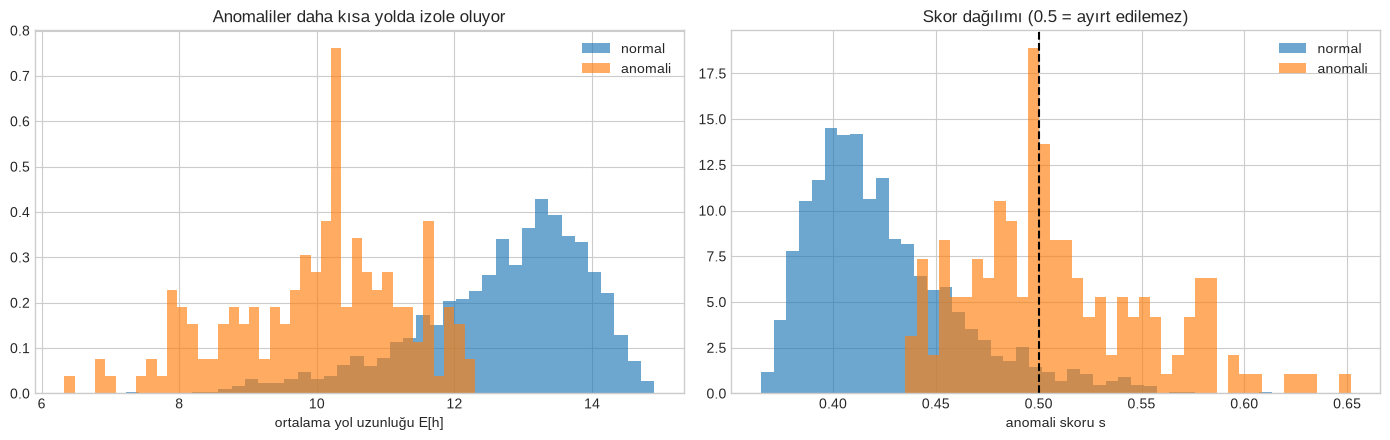

Ortalama yol uzunluğu — normal: 12.71 | anomali: 10.01


In [6]:
# --- Yol uzunluğu: anomaliler gerçekten daha kısa mı? ---
pl = my_if.path_lengths(X_c)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(pl[y_c == 0], bins=40, alpha=0.65, label='normal', density=True); axes[0].hist(pl[y_c == 1], bins=40, alpha=0.65, label='anomali', density=True)
axes[0].set_xlabel('ortalama yol uzunluğu E[h]'); axes[0].legend(); axes[0].set_title('Anomaliler daha kısa yolda izole oluyor')
axes[1].hist(s_my[y_c == 0], bins=40, alpha=0.65, label='normal', density=True); axes[1].hist(s_my[y_c == 1], bins=40, alpha=0.65, label='anomali', density=True)
axes[1].axvline(0.5, ls='--', color='k'); axes[1].set_xlabel('anomali skoru s'); axes[1].legend(); axes[1].set_title('Skor dağılımı (0.5 = ayırt edilemez)')
plt.tight_layout(); plt.show()
print('Ortalama yol uzunluğu — normal: %.2f | anomali: %.2f' % (pl[y_c == 0].mean(), pl[y_c == 1].mean()))

In [7]:
# --- Hiperparametre duyarlılığı (sklearn) ---
rows = []
for ne in [10, 50, 200, 1000]:
    for ms in [32, 128, 256, 'auto']:
        aucs = [evaluate(y_c, -IsolationForest(n_estimators=ne, max_samples=ms, random_state=s).fit(X_c).score_samples(X_c))['AUC'] for s in range(3)]
        rows.append((ne, ms, np.mean(aucs), np.std(aucs)))
sens = pd.DataFrame(rows, columns=['n_estimators', 'max_samples', 'AUC ort.', 'AUC std (3 tohum)'])
display(sens.pivot(index='n_estimators', columns='max_samples', values='AUC ort.').round(4))
print('Tohumlar arası ortalama std: %.4f' % sens['AUC std (3 tohum)'].mean())

# --- Eşik (contamination) etkisi: sıralama aynı, sınıflandırma değişir ---
s_if = -IsolationForest(n_estimators=300, random_state=42).fit(X_c).score_samples(X_c)
rows = []
for cont in [0.02, 0.05, 0.096, 0.15, 0.25]:
    thr = np.quantile(s_if, 1 - cont); pred = (s_if >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y_c, pred).ravel()
    rows.append((cont, tp / (tp + fp), tp / (tp + fn), f1_score(y_c, pred), fp, fn))
display(pd.DataFrame(rows, columns=['contamination', 'precision', 'recall', 'F1', 'yanlış alarm (FP)', 'kaçırılan (FN)']).round(3))
print('YORUM: Isolation Forest hiperparametrelere görece dayanıklı: ≥200 ağaçtan sonra AUC ≈ 0.93 civarında sabitleniyor, çok az ağaç (10) ise daha dalgalı. Eşik ise tamamen iş kararı: contamination yükseldikçe recall artar, precision düşer.')

max_samples,32,128,256,auto
n_estimators,,,,
10,0.7879,0.8508,0.8895,0.8895
50,0.8792,0.9050,0.9300,0.9300
200,0.9244,0.9280,0.9328,0.9328
1000,0.9261,0.9310,0.9283,0.9283


Tohumlar arası ortalama std: 0.0138


,contamination,precision,recall,F1,yanlış alarm (FP),kaçırılan (FN)
0,0.020,0.865,0.182,0.300,5,144
1,0.050,0.609,0.318,0.418,36,120
2,0.096,0.523,0.523,0.523,84,84
3,0.150,0.440,0.688,0.537,154,55
4,0.250,0.347,0.903,0.502,299,17


YORUM: Isolation Forest hiperparametrelere görece dayanıklı: ≥200 ağaçtan sonra AUC ≈ 0.93 civarında sabitleniyor, çok az ağaç (10) ise daha dalgalı. Eşik ise tamamen iş kararı: contamination yükseldikçe recall artar, precision düşer.


## Adım 3 · LOF: Elle Örnek, Sıfırdan Implementasyon ve Yerel–Global Anomali Deneyi

**Ne yapıyoruz?** (1) §4.3'teki $\{1,2,3,10\}$, $k=2$ tablosunu sıfırdan `SimpleLOF` ile üretip `sklearn` ile karşılaştırıyoruz; (2) aynı sınıfı Cardio (ölçekli) üzerinde
`sklearn` ile **maks. mutlak fark** bazında doğruluyoruz; (3) $k$ duyarlılığı; (4) LOF'un varlık sebebi — **yoğunluğu değişen veride** yerel anomalileri Isolation Forest'in ve global Mahalanobis'in kaçırdığını,
LOF'un yakaladığını sentetik veride gösteriyoruz.

In [8]:
class SimpleLOF:
    """LOF (sıfırdan, kaba kuvvet uzaklık matrisi). Yüksek LOF = daha anormal."""
    def __init__(self, k=20):
        self.k = k
    def fit(self, X):
        D = pairwise_distances(X); np.fill_diagonal(D, np.inf)
        self.nbr = np.argsort(D, axis=1)[:, :self.k]                               # k-komşuluk
        self.kdist = D[np.arange(len(X)), self.nbr[:, -1]]                         # k-uzaklık
        reach = np.maximum(self.kdist[self.nbr], D[np.arange(len(X))[:, None], self.nbr])   # reach-dist(A,B)=max(kdist(B), d(A,B))
        self.lrd = 1.0 / reach.mean(axis=1)
        self.lof_ = self.lrd[self.nbr].mean(axis=1) / self.lrd
        return self

# --- §4.3 elle örnek ---
x1 = np.array([[1.], [2.], [3.], [10.]])
toy = SimpleLOF(k=2).fit(x1)
print('k-uzaklıklar:', toy.kdist, '| lrd:', toy.lrd.round(3))
print('Sıfırdan LOF:', toy.lof_.round(3))
print('sklearn  LOF:', (-LocalOutlierFactor(n_neighbors=2).fit(x1).negative_outlier_factor_).round(3))

# --- Cardio (ölçekli): sıfırdan vs sklearn ---
Xc_s = StandardScaler().fit_transform(X_c)
my_lof = SimpleLOF(k=30).fit(Xc_s)
sk_lof = LocalOutlierFactor(n_neighbors=30).fit(Xc_s)
print('\nCardio LOF — sıfırdan vs sklearn, maks. mutlak fark: %.2e' % np.abs(my_lof.lof_ - (-sk_lof.negative_outlier_factor_)).max())
print('Sıfırdan LOF  :', {k: round(v, 3) for k, v in evaluate(y_c, my_lof.lof_).items()})
print('(Cardio zaten standartlaştırılmış olduğundan ölçekleme etkisini bir sonraki hücrede yapay birim farkıyla göstereceğiz.)')

k-uzaklıklar: [2. 1. 2. 8.] | lrd: [0.667 0.5   0.667 0.133]
Sıfırdan LOF: [0.875 1.333 0.875 4.375]
sklearn  LOF: [0.875 1.333 0.875 4.375]



Cardio LOF — sıfırdan vs sklearn, maks. mutlak fark: 1.66e-10
Sıfırdan LOF  : {'AUC': 0.553, 'AP': 0.154, 'P_at_n': np.float64(0.148)}
(Cardio zaten standartlaştırılmış olduğundan ölçekleme etkisini bir sonraki hücrede yapay birim farkıyla göstereceğiz.)


,Yöntem,AUC (orijinal),"AUC (birimleri karıştırılmış, ölçeksiz)",AUC (karışık birim + StandardScaler)
0,Isolation Forest,0.932,0.932,0.932
1,LOF (k=30),0.553,0.629,0.553
2,One-Class SVM,0.872,0.756,0.872


YORUM: Isolation Forest eksen başına bağımsız kesme seçtiği için ölçekten etkilenmez (AUC birebir aynı); mesafe/kernel tabanlı LOF ve OCSVM, en büyük birimli özniteliklerin egemenliğine girer — ölçekleme zorunlu.
Letter: (1600, 32) | anomali: 100 (6.25%)


,k,Cardio AUC,Cardio AP,Letter AUC,Letter AP
0,5,0.503,0.124,0.907,0.551
1,10,0.587,0.175,0.912,0.564
2,20,0.536,0.150,0.898,0.473
3,35,0.578,0.162,0.865,0.365
4,50,0.656,0.184,0.842,0.313
5,100,0.844,0.288,0.800,0.229
6,200,0.923,0.467,0.734,0.169


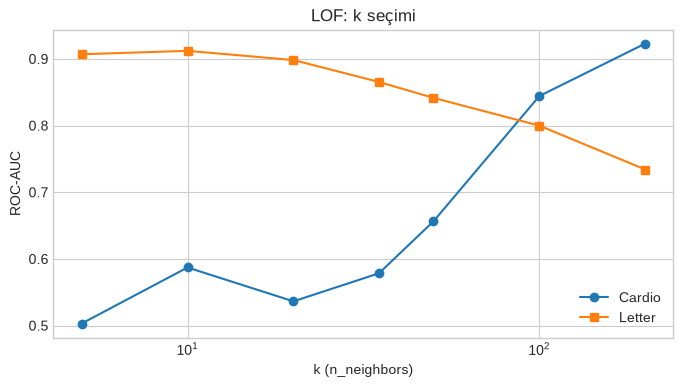

YORUM: En iyi k veri setine göre çok farklı. Letter'da küçük k (5-10) en iyi: anomaliler dağınık, tek tek yerel olarak seyrek. Cardio'da ise AUC k büyüdükçe (200'e kadar) yükseliyor:
       176 patolojik kayıt kendi içinde YOĞUN bir grup oluşturuyor; k bu grubun büyüklüğünden küçükken kayıtlar birbirini komşu görüp "normal" sanıyor (LOF≈1).
       Kural: k, bir anomali KÜMESİNİN beklenen büyüklüğünden büyük seçilmeli — "20-50 ile başla" sezgisi dağınık anomaliler için geçerlidir, kümelenen anomaliler için değil.


In [9]:
# --- Ölçek deneyi: öznitelikleri farklı "birimlere" çevir (cm ↔ m ↔ mm gibi), IF ve LOF ne olur? ---
rs_sc = np.random.RandomState(5); scales = 10 ** rs_sc.uniform(0, 3, X_c.shape[1])      # her öznitelik 1x ... 1000x büyütüldü
X_bad = X_c * scales
rows = []
for nm, fn in [('Isolation Forest', lambda Z: -IsolationForest(n_estimators=300, random_state=0).fit(Z).score_samples(Z)),
               ('LOF (k=30)', lambda Z: -LocalOutlierFactor(n_neighbors=30).fit(Z).negative_outlier_factor_),
               ('One-Class SVM', lambda Z: -OneClassSVM(gamma='scale', nu=0.1).fit(Z).score_samples(Z))]:
    rows.append((nm, evaluate(y_c, fn(X_c))['AUC'], evaluate(y_c, fn(X_bad))['AUC'], evaluate(y_c, fn(StandardScaler().fit_transform(X_bad)))['AUC']))
display(pd.DataFrame(rows, columns=['Yöntem', 'AUC (orijinal)', 'AUC (birimleri karıştırılmış, ölçeksiz)', 'AUC (karışık birim + StandardScaler)']).round(3))
print('YORUM: Isolation Forest eksen başına bağımsız kesme seçtiği için ölçekten etkilenmez (AUC birebir aynı); mesafe/kernel tabanlı LOF ve OCSVM, en büyük birimli özniteliklerin egemenliğine girer — ölçekleme zorunlu.')

# --- k duyarlılığı: Cardio ve Letter ---
letter = pd.read_csv('data/letter.csv'); y_l = letter['label'].to_numpy(); X_l = letter.drop(columns='label').to_numpy(); Xl_s = StandardScaler().fit_transform(X_l)
print('Letter:', X_l.shape, '| anomali: %d (%.2f%%)' % (y_l.sum(), 100 * y_l.mean()))
rows = []
for k in [5, 10, 20, 35, 50, 100, 200]:
    rc = evaluate(y_c, -LocalOutlierFactor(n_neighbors=k).fit(Xc_s).negative_outlier_factor_)
    rl = evaluate(y_l, -LocalOutlierFactor(n_neighbors=k).fit(Xl_s).negative_outlier_factor_)
    rows.append((k, rc['AUC'], rc['AP'], rl['AUC'], rl['AP']))
ktab = pd.DataFrame(rows, columns=['k', 'Cardio AUC', 'Cardio AP', 'Letter AUC', 'Letter AP']); display(ktab.round(3))
fig, ax = plt.subplots(figsize=(8, 4)); ax.plot(ktab['k'], ktab['Cardio AUC'], 'o-', label='Cardio'); ax.plot(ktab['k'], ktab['Letter AUC'], 's-', label='Letter')
ax.set_xscale('log'); ax.set_xlabel('k (n_neighbors)'); ax.set_ylabel('ROC-AUC'); ax.legend(); ax.set_title('LOF: k seçimi'); plt.show()
print('YORUM: En iyi k veri setine göre çok farklı. Letter\'da küçük k (5-10) en iyi: anomaliler dağınık, tek tek yerel olarak seyrek. Cardio\'da ise AUC k büyüdükçe (200\'e kadar) yükseliyor:')
print('       176 patolojik kayıt kendi içinde YOĞUN bir grup oluşturuyor; k bu grubun büyüklüğünden küçükken kayıtlar birbirini komşu görüp "normal" sanıyor (LOF≈1).')
print('       Kural: k, bir anomali KÜMESİNİN beklenen büyüklüğünden büyük seçilmeli — "20-50 ile başla" sezgisi dağınık anomaliler için geçerlidir, kümelenen anomaliler için değil.')

,Yöntem,Yerel anomalilerin ort. sırası (6 nokta),Global anomalilerin ort. sırası (2 nokta)
0,Isolation Forest,43.8,1.5
1,LOF (k=30),5.5,1.5
2,Mahalanobis,280.7,1.5


(Sıra 1 = en şüpheli; 608 nokta içinde 6 yerel + 2 global anomali. Mükemmel bir dedektör 8 anomaliyi en üst 8 sıraya koyar: global 2 nokta ort. sıra 1.5, yerel 6 nokta ort. sıra 5.5.)
YORUM: Global yöntemlerin hepsi uzak noktaları bulur; ama yoğun kümenin hemen dışındaki yerel anomalileri yalnızca LOF üst sıralara koyar — Isolation Forest ve Mahalanobis bu noktaları seyrek kümenin üyeleri gibi görür.


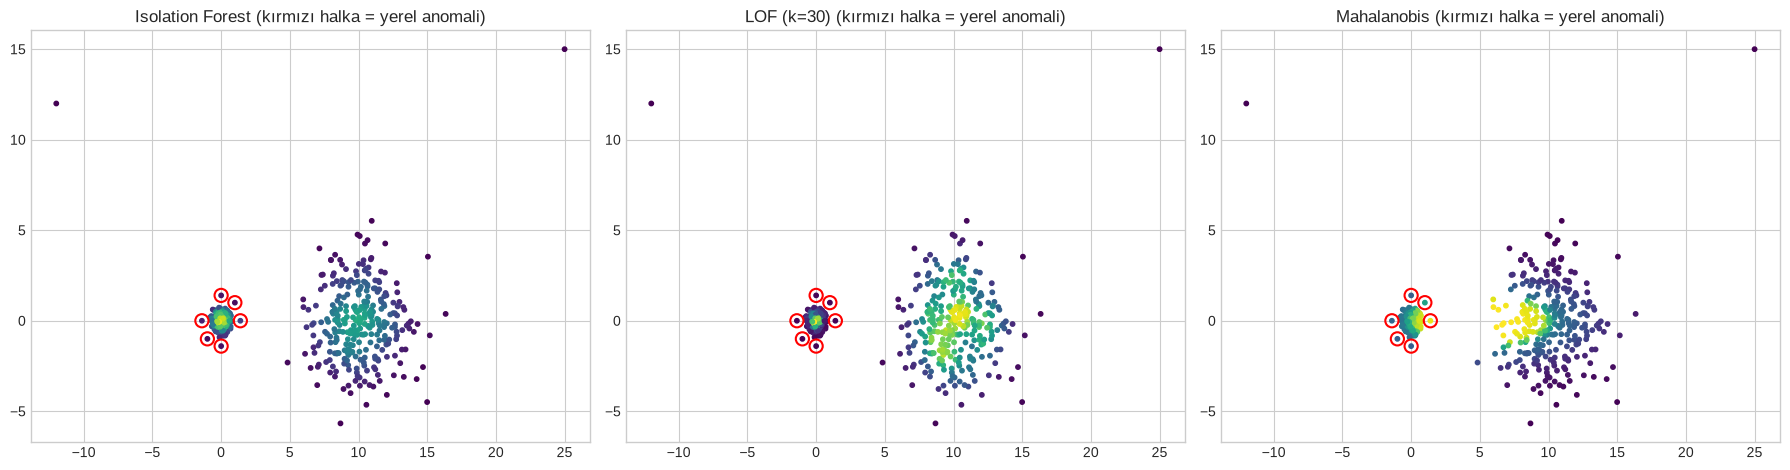

In [10]:
# --- Yerel anomali deneyi: yoğun + seyrek kümeler ---
rs = np.random.RandomState(0)
dense = rs.randn(300, 2) * 0.3                          # yoğun küme (std 0.3), merkez (0,0)
sparse = rs.randn(300, 2) * 2.0 + [10, 0]               # seyrek küme (std 2.0), merkez (10,0)
local_out = np.array([[1.4, 0], [-1.4, 0], [0, 1.4], [0, -1.4], [1.0, 1.0], [-1.0, -1.0]])   # yoğun kümenin hemen dışında (yerel anomali)
global_out = np.array([[25, 15], [-12, 12]])            # çok uzak (global anomali)
Xs = np.vstack([dense, sparse, local_out, global_out]); ys = np.r_[np.zeros(600), np.ones(len(local_out) + len(global_out))].astype(int)
is_local = np.r_[np.zeros(600, bool), np.ones(len(local_out), bool), np.zeros(len(global_out), bool)]

s_if2 = -IsolationForest(n_estimators=300, random_state=0).fit(Xs).score_samples(Xs)
s_lof2 = -LocalOutlierFactor(n_neighbors=30).fit(Xs).negative_outlier_factor_
s_mh2 = EmpiricalCovariance().fit(Xs).mahalanobis(Xs)

def rank_of(s, mask):   # maskedeki noktaların (1 = en şüpheli) ortalama sırası
    r = stats.rankdata(-s); return r[mask].mean()
rows = [(n, rank_of(s, is_local), rank_of(s, np.r_[np.zeros(600 + len(local_out), bool), np.ones(len(global_out), bool)]))
        for n, s in [('Isolation Forest', s_if2), ('LOF (k=30)', s_lof2), ('Mahalanobis', s_mh2)]]
display(pd.DataFrame(rows, columns=['Yöntem', 'Yerel anomalilerin ort. sırası (6 nokta)', 'Global anomalilerin ort. sırası (2 nokta)']).round(1))
print('(Sıra 1 = en şüpheli; 608 nokta içinde 6 yerel + 2 global anomali. Mükemmel bir dedektör 8 anomaliyi en üst 8 sıraya koyar: global 2 nokta ort. sıra 1.5, yerel 6 nokta ort. sıra 5.5.)')
print('YORUM: Global yöntemlerin hepsi uzak noktaları bulur; ama yoğun kümenin hemen dışındaki yerel anomalileri yalnızca LOF üst sıralara koyar — Isolation Forest ve Mahalanobis bu noktaları seyrek kümenin üyeleri gibi görür.')

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, s, ttl in zip(axes, [s_if2, s_lof2, s_mh2], ['Isolation Forest', 'LOF (k=30)', 'Mahalanobis']):
    sc = ax.scatter(Xs[:, 0], Xs[:, 1], c=stats.rankdata(s) / len(s), cmap='viridis_r', s=10)
    ax.scatter(local_out[:, 0], local_out[:, 1], facecolors='none', edgecolors='red', s=90, linewidths=1.5); ax.set_title(ttl + ' (kırmızı halka = yerel anomali)')
plt.tight_layout(); plt.show()

## Adım 4 · One-Class SVM: $\nu$ Özelliği, $\gamma$ Duyarlılığı ve Yarı-Denetimli Kullanım

**Ne yapıyoruz?** (1) §5.2'deki $\nu$ özelliğini doğruluyoruz: eğitim verisinde dışarıda kalan oran $\le\nu$, destek vektörü oranı $\ge\nu$. (2) Cardio'da ölçekli veride $\nu\times\gamma$ ızgarası.
(3) **Yarı-denetimli kurulum:** Yalnızca *normal* kayıtlarla eğitim, sonra hem yeni normalleri hem tüm anomalileri skorlama — ve eğitim verisi **kirlenmişse** (anomali içeriyorsa) performansın nasıl düştüğü.

In [11]:
# --- ν özelliği: Gauss yığın, 1000 nokta ---
Xg = np.random.RandomState(1).randn(1000, 2)
rows = []
for nu in [0.01, 0.05, 0.1, 0.2, 0.5]:
    m = OneClassSVM(kernel='rbf', gamma='scale', nu=nu).fit(Xg); dfn = m.decision_function(Xg)
    rows.append((nu, (dfn < -1e-3).mean(), (m.predict(Xg) == -1).mean(), len(m.support_) / len(Xg)))
display(pd.DataFrame(rows, columns=['ν', 'Kesin dışarıda (karar fn. < −1e-3), ≤ ν', '`predict`=-1 oranı', 'Destek vektörü oranı (≥ ν)']).round(3))
print('YORUM: ν özelliği "kesin dışarıda" oranı için geçerli (≤ ν ≤ destek vektörü oranı). `predict`, sınırın üzerindeki (karar fn. ≈ 0, yani "serbest" destek vektörleri) noktaları sayısal toleransla -1 yapabildiği için')
print('       küçük ν\'de ν\'yü aşabilir — ν\'yü "anomali oranı garantisi" değil, sınırın genişliğini ayarlayan bir düğme olarak okuyun.')

# --- Cardio: ν × γ ızgarası (ölçekli) ---
g0 = 1 / (Xc_s.shape[1] * Xc_s.var())            # gamma='scale' değeri
rows = []
for nu in [0.02, 0.05, 0.1, 0.2]:
    for gm in [0.1, 0.3, 1, 3]:
        s = -OneClassSVM(kernel='rbf', gamma=gm * g0, nu=nu).fit(Xc_s).score_samples(Xc_s)
        rows.append((nu, gm, evaluate(y_c, s)['AUC']))
display(pd.DataFrame(rows, columns=['ν', 'γ / γ_scale', 'AUC']).pivot(index='ν', columns='γ / γ_scale', values='AUC').round(3))
print('gamma="scale" değeri: %.4f' % g0)

,ν,"Kesin dışarıda (karar fn. < −1e-3), ≤ ν",`predict`=-1 oranı,Destek vektörü oranı (≥ ν)
0,0.01,0.000,0.056,0.063
1,0.05,0.036,0.061,0.069
2,0.10,0.082,0.101,0.113
3,0.20,0.194,0.199,0.206
4,0.50,0.497,0.499,0.504


YORUM: ν özelliği "kesin dışarıda" oranı için geçerli (≤ ν ≤ destek vektörü oranı). `predict`, sınırın üzerindeki (karar fn. ≈ 0, yani "serbest" destek vektörleri) noktaları sayısal toleransla -1 yapabildiği için
       küçük ν'de ν'yü aşabilir — ν'yü "anomali oranı garantisi" değil, sınırın genişliğini ayarlayan bir düğme olarak okuyun.


γ / γ_scale,0.1,0.3,1.0,3.0
ν,,,,
0.02,0.819,0.855,0.868,0.775
0.05,0.882,0.888,0.871,0.785
0.10,0.907,0.897,0.872,0.793
0.20,0.927,0.921,0.887,0.817


gamma="scale" değeri: 0.0500


In [12]:
# --- Yarı-denetimli: sadece normal veriyle eğit ---
idx_norm, idx_anom = np.where(y_c == 0)[0], np.where(y_c == 1)[0]
tr_norm, te_norm = train_test_split(idx_norm, test_size=0.3, random_state=42)
test_idx = np.r_[te_norm, idx_anom]; y_test = y_c[test_idx]

def fit_score(train_idx, nu=0.05):
    sc = StandardScaler().fit(X_c[train_idx])
    m = OneClassSVM(kernel='rbf', gamma='scale', nu=nu).fit(sc.transform(X_c[train_idx]))
    return -m.score_samples(sc.transform(X_c[test_idx]))

clean = fit_score(tr_norm)
# kirli eğitim: normal eğitim kümesine, anomalilerin yarısını ekle (test'te kalan anomaliler de ölçüm için kullanılıyor; adil olması için kirletilen anomalileri testten çıkar)
rs_ = np.random.RandomState(0); polluted_anoms = rs_.choice(idx_anom, size=len(idx_anom) // 2, replace=False)
tr_dirty = np.r_[tr_norm, polluted_anoms]
test_keep = ~np.isin(test_idx, polluted_anoms)
dirty_scores = fit_score(tr_dirty)
print('Eğitim: %d normal | Test: %d normal + %d anomali' % (len(tr_norm), len(te_norm), len(idx_anom)))
print('Temiz eğitim (yalnızca normal)             -> AUC = %.3f, AP = %.3f' % (roc_auc_score(y_test, clean), average_precision_score(y_test, clean)))
print('Kirli eğitim (+%d anomali, kirletilen test dışı) -> AUC = %.3f, AP = %.3f' % (len(polluted_anoms), roc_auc_score(y_test[test_keep], dirty_scores[test_keep]), average_precision_score(y_test[test_keep], dirty_scores[test_keep])))
print('Aynı test alt kümesinde temiz eğitim        -> AUC = %.3f' % roc_auc_score(y_test[test_keep], clean[test_keep]))
print('YORUM: Yarı-denetimli kurulum (normal-only) üretim için en doğal ayar: model "normalin nasıl göründüğünü" öğrenir. Eğitim verisinin kirlenmesi sınırı genişletip sapmaları normalleştirir.')

Eğitim: 1158 normal | Test: 497 normal + 176 anomali
Temiz eğitim (yalnızca normal)             -> AUC = 0.981, AP = 0.945
Kirli eğitim (+88 anomali, kirletilen test dışı) -> AUC = 0.849, AP = 0.513
Aynı test alt kümesinde temiz eğitim        -> AUC = 0.979
YORUM: Yarı-denetimli kurulum (normal-only) üretim için en doğal ayar: model "normalin nasıl göründüğünü" öğrenir. Eğitim verisinin kirlenmesi sınırı genişletip sapmaları normalleştirir.


## Adım 5 · Elliptic Envelope / MCD: Maskeleme, Robust Kovaryans ve Yüksek Boyut Sınırı

**Ne yapıyoruz?** (1) **Maskeleme** deneyi: korelasyonlu 2B Gauss verisine %20 aykırı küme ekleyip klasik ve MCD tabanlı Mahalanobis'in kaç aykırıyı yakaladığını sayıyoruz.
(2) $\chi^2$ eşiği ve `EllipticEnvelope`'un `contamination` ile ilişkisi. (3) Cardio'da klasik / MCD karşılaştırması. (4) Yüksek boyut sınırı: **Arrhythmia** ($n=452,\ p=274$) üzerinde MCD'nin uyarı verdiği durumu **bilinçli olarak** yakalayıp gösteriyoruz ve PCA ile çözümünü deniyoruz.

Gerçek aykırı: 100 | eşik χ²(2, .975) = 7.38
Klasik Mahalanobis ile işaretlenen aykırı sayısı  : 0 / 100  (yanlış alarm: 6)
MCD (robust) ile işaretlenen aykırı sayısı        : 100 / 100  (yanlış alarm: 8)
Klasik ortalama: [ 1.   -0.73] | MCD ortalaması: [0.03 0.06] | gerçek merkez: [0 0]


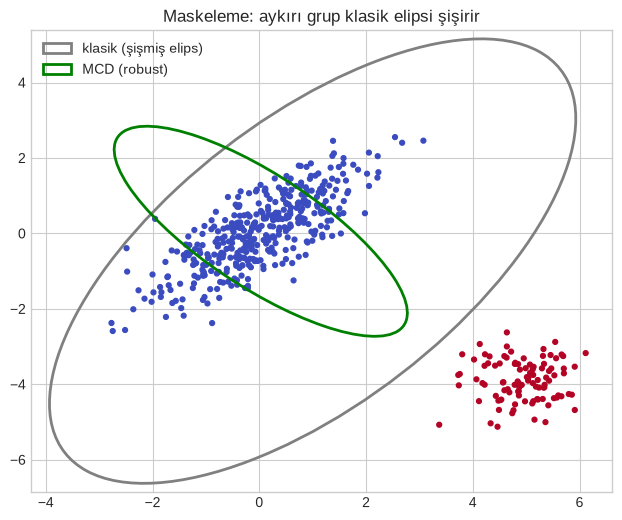

In [13]:
# --- (1) Maskeleme ---
rs = np.random.RandomState(3)
good = rs.multivariate_normal([0, 0], [[1, 0.8], [0.8, 1]], 400)
bad = rs.multivariate_normal([5, -4], [[0.3, 0], [0, 0.3]], 100)           # %20 aykırı küme
Xm = np.vstack([good, bad]); ym = np.r_[np.zeros(400), np.ones(100)].astype(int)
thr2 = stats.chi2.ppf(0.975, 2)
d_emp = EmpiricalCovariance().fit(Xm).mahalanobis(Xm)
mcd = MinCovDet(random_state=0).fit(Xm); d_mcd = mcd.mahalanobis(Xm)
print('Gerçek aykırı: 100 | eşik χ²(2, .975) = %.2f' % thr2)
print('Klasik Mahalanobis ile işaretlenen aykırı sayısı  : %d / 100  (yanlış alarm: %d)' % (((d_emp > thr2) & (ym == 1)).sum(), ((d_emp > thr2) & (ym == 0)).sum()))
print('MCD (robust) ile işaretlenen aykırı sayısı        : %d / 100  (yanlış alarm: %d)' % (((d_mcd > thr2) & (ym == 1)).sum(), ((d_mcd > thr2) & (ym == 0)).sum()))
print('Klasik ortalama: %s | MCD ortalaması: %s | gerçek merkez: [0 0]' % (EmpiricalCovariance().fit(Xm).location_.round(2), mcd.location_.round(2)))

from matplotlib.patches import Ellipse
def draw_ellipse(ax, mean, cov, nstd, **kw):
    vals, vecs = np.linalg.eigh(cov); ang = np.degrees(np.arctan2(*vecs[:, 1][::-1])); w, h = 2 * nstd * np.sqrt(vals)
    ax.add_patch(Ellipse(mean, w, h, angle=ang, fill=False, **kw))
fig, ax = plt.subplots(figsize=(7.5, 6)); ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap='coolwarm', s=12)
emp_fit = EmpiricalCovariance().fit(Xm); r = np.sqrt(thr2)
draw_ellipse(ax, emp_fit.location_, emp_fit.covariance_, r, color='gray', lw=2, label='klasik (şişmiş elips)')
draw_ellipse(ax, mcd.location_, mcd.covariance_, r, color='green', lw=2, label='MCD (robust)')
ax.legend(); ax.set_title('Maskeleme: aykırı grup klasik elipsi şişirir'); plt.show()

In [14]:
# --- (2)-(3) Cardio: klasik vs MCD vs EllipticEnvelope ---
t0 = time.time(); mcd_c, n_warn_c = fit_mcd(X_c); t_mcd = time.time() - t0
s_mcd_c = mcd_c.mahalanobis(X_c)
with warnings.catch_warnings(record=True) as w_ee:
    warnings.simplefilter('always'); ee = EllipticEnvelope(contamination=0.096, random_state=0).fit(X_c)
pred_ee = (ee.predict(X_c) == -1).astype(int)
print('Cardio — klasik Mahalanobis :', {k: round(v, 3) for k, v in evaluate(y_c, score_maha).items()})
print('Cardio — MCD Mahalanobis (support_fraction=0.75; varsayılan ~0.51 değeri bu veride sayısal uyarı üretiyor, bkz. E4):', {k: round(v, 3) for k, v in evaluate(y_c, s_mcd_c).items()}, '| MCD süre: %.1f sn' % t_mcd)
print('EllipticEnvelope(contamination=0.096): işaretlenen=%d | precision=%.3f | recall=%.3f' % (pred_ee.sum(), (pred_ee & y_c).sum() / pred_ee.sum(), (pred_ee & y_c).sum() / y_c.sum()))
print('MCD fit sırasında sklearn sayısal uyarısı: support_fraction=0.75 -> %d adet | EllipticEnvelope (varsayılan ≈0.51) -> %d adet ("Determinant has increased")' % (n_warn_c, len(w_ee)))
print('EllipticEnvelope eşiği (contamination=0.096 ile kalibre, Mahalanobis² cinsinden): %.1f  vs  teorik χ²(%d, 0.975) = %.1f' % (np.quantile(ee.mahalanobis(X_c), 1 - 0.096), X_c.shape[1], stats.chi2.ppf(0.975, X_c.shape[1])))
print('YORUM: Cardio\'da MCD klasik Mahalanobis\'ten DAHA KÖTÜ (AUC %.2f vs %.2f) ve kalibre eşik teorik χ²\'nin ~25 katı: veri Gauss\'tan çok uzak (çarpık, sıfır-yığılımlı öznitelikler),' % (evaluate(y_c, s_mcd_c)['AUC'], evaluate(y_c, score_maha)['AUC']))
print('       MCD\'nin C-adımları da sayısal olarak kararsızlaşıyor (yukarıdaki uyarılar). Robust olmak, model varsayımı yanlışken kurtarmaz — varsayımı doğrulamadan MCD\'ye güvenmeyin.')

# --- (4) Yüksek boyut: Arrhythmia ---
arr = pd.read_csv('data/arrhythmia.csv'); y_a = arr['label'].to_numpy(); X_a = arr.drop(columns='label').to_numpy()
n_const = int((X_a.std(0) == 0).sum())
print('\nArrhythmia:', X_a.shape, '| anomali: %d (%.1f%%) | sabit öznitelik: %d' % (y_a.sum(), 100 * y_a.mean(), n_const))
with warnings.catch_warnings(record=True) as wlist:
    warnings.simplefilter('always')
    try:
        s_arr = MinCovDet(random_state=0).fit(X_a).mahalanobis(X_a); auc_arr = evaluate(y_a, s_arr)['AUC']
    except Exception as e:
        auc_arr = np.nan; print('MCD hata:', type(e).__name__, str(e)[:120])
print('Ham 274 boyutta MCD (varsayılan ayar): AUC = %.3f | yakalanan uyarı sayısı = %d' % (auc_arr, len(wlist)))
for w in wlist[:2]: print('  uyarı ->', str(w.message)[:140])
Xa_p = PCA(n_components=15, random_state=0).fit_transform(StandardScaler().fit_transform(X_a[:, X_a.std(0) > 0]))
m_a, nw_a = fit_mcd(Xa_p)
print('PCA(15) sonrası MCD: AUC = %.3f | sayısal uyarı: %d' % (evaluate(y_a, m_a.mahalanobis(Xa_p))['AUC'], nw_a))
print('YORUM: Robust kovaryans p ≪ n ister; p büyükse önce boyut indirgeme (PCA) uygulanır — 18\'deki araçların anomali tespitinde de ön adım olduğuna dikkat.')

Cardio — klasik Mahalanobis : {'AUC': 0.896, 'AP': 0.464, 'P_at_n': np.float64(0.455)}
Cardio — MCD Mahalanobis (support_fraction=0.75; varsayılan ~0.51 değeri bu veride sayısal uyarı üretiyor, bkz. E4): {'AUC': 0.8, 'AP': 0.319, 'P_at_n': np.float64(0.409)} | MCD süre: 0.5 sn
EllipticEnvelope(contamination=0.096): işaretlenen=176 | precision=0.375 | recall=0.375
MCD fit sırasında sklearn sayısal uyarısı: support_fraction=0.75 -> 4 adet | EllipticEnvelope (varsayılan ≈0.51) -> 46 adet ("Determinant has increased")
EllipticEnvelope eşiği (contamination=0.096 ile kalibre, Mahalanobis² cinsinden): 850.3  vs  teorik χ²(20, 0.975) = 34.2
YORUM: Cardio'da MCD klasik Mahalanobis'ten DAHA KÖTÜ (AUC 0.80 vs 0.90) ve kalibre eşik teorik χ²'nin ~25 katı: veri Gauss'tan çok uzak (çarpık, sıfır-yığılımlı öznitelikler),
       MCD'nin C-adımları da sayısal olarak kararsızlaşıyor (yukarıdaki uyarılar). Robust olmak, model varsayımı yanlışken kurtarmaz — varsayımı doğrulamadan MCD'ye güvenmeyin.

Arrh

Ham 274 boyutta MCD (varsayılan ayar): AUC = 0.770 | yakalanan uyarı sayısı = 1
  uyarı -> The covariance matrix associated to your dataset is not full rank
PCA(15) sonrası MCD: AUC = 0.785 | sayısal uyarı: 0
YORUM: Robust kovaryans p ≪ n ister; p büyükse önce boyut indirgeme (PCA) uygulanır — 18'deki araçların anomali tespitinde de ön adım olduğuna dikkat.


## Adım 6 · Büyük Karşılaştırma: 3 Veri Seti × 6 Yöntem ve Rank-Averaging Topluluğu

**Ne yapıyoruz?** Cardio, Letter ve Arrhythmia'da aynı protokolle (denetimsiz: tüm veriye `fit`, aynı veriyi skorla; etiket yalnızca ölçüm) altı skoru üretiyoruz:
Isolation Forest, LOF ($k=35$), One-Class SVM ($\nu=0.1$), MCD-Mahalanobis, klasik Mahalanobis ve **sıra ortalaması topluluğu** (IF+LOF+OCSVM+MCD skorlarının sıra yüzdelerinin ortalaması).
Arrhythmia için ($p=274$) tüm yöntemler standartlaştırılmış + PCA(15) girdisiyle çalışıyor (MCD'nin çalışabilmesi için). MCD için `support_fraction=0.75` kullanıyoruz (varsayılan ≈0.51 bu veri setlerinde sayısal uyarı üretir; E4'te bu parametreyi inceleyeceksin).

In [15]:
def rank01(s): return (stats.rankdata(s) - 1) / (len(s) - 1)

def all_scores(X, y, pca_dim=None, k=35, nu=0.1, seed=0):
    Xs_ = StandardScaler().fit_transform(X[:, X.std(0) > 0])
    Xin = PCA(pca_dim, random_state=seed).fit_transform(Xs_) if pca_dim else Xs_
    out, times = {}, {}
    def timed(name, fn):
        t0 = time.time(); out[name] = fn(); times[name] = time.time() - t0
    timed('Isolation Forest', lambda: -IsolationForest(n_estimators=300, random_state=seed).fit(Xin).score_samples(Xin))
    timed('LOF', lambda: -LocalOutlierFactor(n_neighbors=k).fit(Xin).negative_outlier_factor_)
    timed('One-Class SVM', lambda: -OneClassSVM(kernel='rbf', gamma='scale', nu=nu).fit(Xin).score_samples(Xin))
    def _mcd():
        m, nw = fit_mcd(Xin, 0.75, seed); out['_mcd_warn'] = nw; return m.mahalanobis(Xin)
    timed('MCD (robust)', _mcd)
    timed('Mahalanobis (klasik)', lambda: EmpiricalCovariance().fit(Xin).mahalanobis(Xin))
    out['Topluluk (IF+LOF+OCSVM+MCD)'] = np.mean([rank01(out[n]) for n in ['Isolation Forest', 'LOF', 'One-Class SVM', 'MCD (robust)']], axis=0)
    times['Topluluk (IF+LOF+OCSVM+MCD)'] = sum(times[n] for n in ['Isolation Forest', 'LOF', 'One-Class SVM', 'MCD (robust)'])
    return out, times

bench = {}
for name, (X, y, pdim) in {'Cardio': (X_c, y_c, None), 'Letter': (X_l, y_l, None), 'Arrhythmia': (X_a, y_a, 15)}.items():
    sc, tm = all_scores(X, y, pca_dim=pdim); nw = sc.pop('_mcd_warn'); bench[name] = (sc, tm, y); print(f'{name}: MCD sayısal uyarı sayısı = {nw}')

rows = []
for ds, (sc, tm, y) in bench.items():
    for meth, s in sc.items():
        m = evaluate(y, s); rows.append((ds, meth, m['AUC'], m['AP'], m['P_at_n'], tm[meth]))
bt = pd.DataFrame(rows, columns=['Veri', 'Yöntem', 'ROC-AUC', 'AP', 'Precision@n', 'Süre (sn)'])
display(bt.pivot(index='Yöntem', columns='Veri', values='ROC-AUC').round(3).assign(Ortalama=lambda d: d.mean(axis=1)).sort_values('Ortalama', ascending=False))
display(bt.pivot(index='Yöntem', columns='Veri', values='AP').round(3))
print('Anomali oranları (AP için rastgele tabanı): ' + ', '.join(f'{ds}={bench[ds][2].mean():.3f}' for ds in bench))

Cardio: MCD sayısal uyarı sayısı = 36


Letter: MCD sayısal uyarı sayısı = 0


Arrhythmia: MCD sayısal uyarı sayısı = 0


Veri,Arrhythmia,Cardio,Letter,Ortalama
Yöntem,,,,
Mahalanobis (klasik),0.813,0.896,0.804,0.837667
Topluluk (IF+LOF+OCSVM+MCD),0.804,0.846,0.765,0.805000
MCD (robust),0.785,0.805,0.812,0.800667
Isolation Forest,0.803,0.932,0.630,0.788333
LOF,0.811,0.578,0.865,0.751333
One-Class SVM,0.769,0.872,0.566,0.735667


Veri,Arrhythmia,Cardio,Letter
Yöntem,,,
Isolation Forest,0.417,0.609,0.090
LOF,0.450,0.162,0.365
MCD (robust),0.408,0.313,0.178
Mahalanobis (klasik),0.440,0.464,0.227
One-Class SVM,0.382,0.404,0.132
Topluluk (IF+LOF+OCSVM+MCD),0.432,0.372,0.153


Anomali oranları (AP için rastgele tabanı): Cardio=0.096, Letter=0.062, Arrhythmia=0.146


In [16]:
# Veri başına en iyi ve en kötü yöntem ve genel çıkarım
piv = bt.pivot(index='Yöntem', columns='Veri', values='ROC-AUC')
for ds in piv.columns: print(f'{ds:11s} en iyi: {piv[ds].idxmax():30s} ({piv[ds].max():.3f}) | en kötü: {piv[ds].idxmin():22s} ({piv[ds].min():.3f})')
mean_auc = piv.mean(axis=1).sort_values(ascending=False); worst = piv.min(axis=1)
print('\nOrtalama AUC sıralaması :', {k: round(v, 3) for k, v in mean_auc.items()})
print('En kötü veri setindeki AUC:', {k: round(v, 3) for k, v in worst.sort_values(ascending=False).items()})
print('\nYORUM: "Her yerde kazanan tek yöntem yok" (No Free Lunch): Cardio\'da Isolation Forest, Letter\'da LOF (yerel yoğunluk) önde. Dikkat çekici bulgular:')
print('  (1) Klasik Mahalanobis bu üç sette ortalamada ZİRVEDE — gelişmiş yöntem her zaman daha iyi değildir; basit çizgiyi her zaman rapora koyun.')
print('  (2) Sıra ortalaması topluluğu hiçbir veri setinde birinci olmadı, ama tek tek yöntemlerin çöktüğü yerleri (Letter\'da IF 0.63, Cardio\'da LOF 0.58) yumuşatıyor: yapıyı bilmediğinizde "sigorta" işlevi görür.')

Arrhythmia  en iyi: Mahalanobis (klasik)           (0.813) | en kötü: One-Class SVM          (0.769)
Cardio      en iyi: Isolation Forest               (0.932) | en kötü: LOF                    (0.578)
Letter      en iyi: LOF                            (0.865) | en kötü: One-Class SVM          (0.566)

Ortalama AUC sıralaması : {'Mahalanobis (klasik)': 0.838, 'Topluluk (IF+LOF+OCSVM+MCD)': 0.805, 'MCD (robust)': 0.801, 'Isolation Forest': 0.789, 'LOF': 0.752, 'One-Class SVM': 0.736}
En kötü veri setindeki AUC: {'Mahalanobis (klasik)': 0.804, 'MCD (robust)': 0.785, 'Topluluk (IF+LOF+OCSVM+MCD)': 0.765, 'Isolation Forest': 0.63, 'LOF': 0.578, 'One-Class SVM': 0.566}

YORUM: "Her yerde kazanan tek yöntem yok" (No Free Lunch): Cardio'da Isolation Forest, Letter'da LOF (yerel yoğunluk) önde. Dikkat çekici bulgular:
  (1) Klasik Mahalanobis bu üç sette ortalamada ZİRVEDE — gelişmiş yöntem her zaman daha iyi değildir; basit çizgiyi her zaman rapora koyun.
  (2) Sıra ortalaması topluluğu hiçbi

## Adım 7 · Görselleştirme: Yakalanan ve Kaçırılan Anomaliler

**Ne yapıyoruz?** Cardio'yu 2B PCA düzlemine çizip her yöntemin **en şüpheli $n$** kaydını ($n$ = gerçek anomali sayısı = 176) işaretliyoruz: yeşil = doğru yakalanan, kırmızı çarpı = yanlış alarm,
siyah halka = kaçırılan gerçek anomali. Amaç, yöntemlerin **hangi anomalileri** yakaladığının/kaçırdığının örtüşüp örtüşmediğine bakmak (topluluğun neden işe yaradığını görmek).

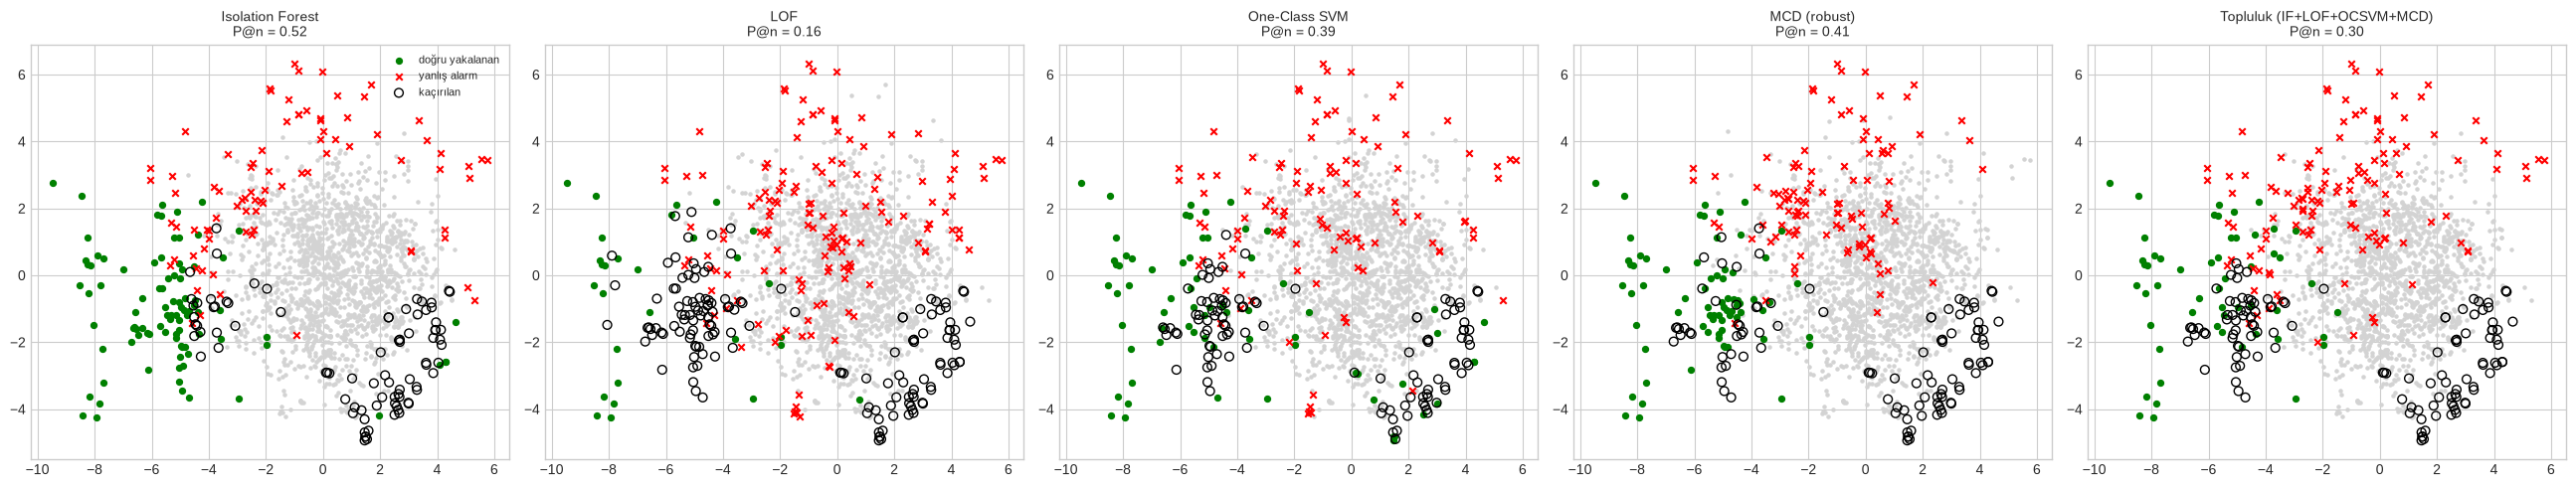

176 gerçek anomalinin kaç yöntem tarafından yakalandığı (4 temel yöntem): {np.int64(0): np.int64(63), np.int64(1): np.int64(38), np.int64(2): np.int64(28), np.int64(3): np.int64(21), np.int64(4): np.int64(26)}
Hiçbirinin yakalayamadığı anomali oranı: 35.8%  |  en az birinin yakaladığı: 64.2%


In [17]:
sc_c = bench['Cardio'][0]
Zp = PCA(2, random_state=0).fit_transform(StandardScaler().fit_transform(X_c))
n_anom = int(y_c.sum()); names = ['Isolation Forest', 'LOF', 'One-Class SVM', 'MCD (robust)', 'Topluluk (IF+LOF+OCSVM+MCD)']
fig, axes = plt.subplots(1, 5, figsize=(26, 5)); caught = {}
for ax, nm in zip(axes, names):
    top = np.zeros(len(y_c), bool); top[np.argsort(sc_c[nm])[::-1][:n_anom]] = True
    ax.scatter(Zp[~top & (y_c == 0), 0], Zp[~top & (y_c == 0), 1], s=5, c='lightgray')
    ax.scatter(Zp[top & (y_c == 1), 0], Zp[top & (y_c == 1), 1], s=18, c='green', label='doğru yakalanan')
    ax.scatter(Zp[top & (y_c == 0), 0], Zp[top & (y_c == 0), 1], s=22, c='red', marker='x', label='yanlış alarm')
    ax.scatter(Zp[~top & (y_c == 1), 0], Zp[~top & (y_c == 1), 1], s=40, facecolors='none', edgecolors='black', label='kaçırılan')
    ax.set_title(f'{nm}\nP@n = {y_c[top].mean():.2f}', fontsize=10); caught[nm] = top & (y_c == 1)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# örtüşme: her anomaliyi kaç yöntem yakaladı?
M = np.vstack([caught[n][y_c == 1] for n in names[:4]])
print('176 gerçek anomalinin kaç yöntem tarafından yakalandığı (4 temel yöntem):', dict(zip(*np.unique(M.sum(0), return_counts=True))))
print('Hiçbirinin yakalayamadığı anomali oranı: %.1f%%  |  en az birinin yakaladığı: %.1f%%' % (100 * (M.sum(0) == 0).mean(), 100 * (M.sum(0) > 0).mean()))

## Adım 8 · Zaman Serisi: NYC Taksi Talebi (Numenta Anomaly Benchmark)

**Ne yapıyoruz?** **NAB `nyc_taxi`** (Lavin & Ahmad 2015; NYC Taxi & Limousine Commission verisinden): 1 Temmuz 2014 – 31 Ocak 2015 arası, **yarım saatlik yolculuk sayısı** (10.320 nokta).
Gerçek, belgelenmiş 5 olay var (etiket pencereleri `nab_windows.json`): NYC Maratonu (1-2 Kasım), Şükran Günü (27 Kasım), Noel (25 Aralık), Yılbaşı (1 Ocak), kar fırtınası (26-27 Ocak).
Boru hattı (§8): (1) haftanın günü × yarım-saat dilimine göre **medyan taban çizgisi** → artık, (2) MAD ile robust ölçekleme, (3) kayan pencere öznitelikleri (kısa: 3 saat, uzun: 24 saat),
(4) Isolation Forest, (5) **günlük toplulaştırma** ile olay düzeyi değerlendirme. Kıyas çizgisi: ham değer üzerinde 7 günlük kayan $z$-skoru.

In [18]:
import json
taxi = pd.read_csv('data/nyc_taxi.csv', parse_dates=['timestamp']); taxi = taxi.sort_values('timestamp').reset_index(drop=True)
windows = json.load(open('data/nab_windows.json'))['realKnownCause/nyc_taxi.csv']
taxi['label'] = 0
for a, b in windows: taxi.loc[(taxi.timestamp >= a) & (taxi.timestamp <= b), 'label'] = 1
print('Nokta:', len(taxi), '| aralık:', taxi.timestamp.min(), '->', taxi.timestamp.max(), '| anomali penceresi içindeki nokta: %d (%.1f%%)' % (taxi.label.sum(), 100 * taxi.label.mean()))
print('Etiket pencereleri:'); [print('  ', a[:16], '->', b[:16]) for a, b in windows]

# (1) mevsimsel taban + artık
taxi['dow'] = taxi.timestamp.dt.day_of_week; taxi['slot'] = taxi.timestamp.dt.hour * 2 + taxi.timestamp.dt.minute // 30
taxi['base'] = taxi.groupby(['dow', 'slot'])['value'].transform('median')
taxi['resid'] = taxi['value'] - taxi['base']
mad = np.median(np.abs(taxi['resid'] - taxi['resid'].median())) * 1.4826
taxi['rz'] = taxi['resid'] / mad
# (3) pencere öznitelikleri
taxi['rz_m6'] = taxi['rz'].rolling(6, min_periods=1).mean(); taxi['rz_s6'] = taxi['rz'].rolling(6, min_periods=2).std().fillna(0)
taxi['rz_m48'] = taxi['rz'].rolling(48, min_periods=1).mean()
feat = ['rz', 'rz_m6', 'rz_s6', 'rz_m48']
print('\nRobust ölçek (MAD) = %.0f yolculuk | artık rz aralığı: %.1f ... %.1f' % (mad, taxi.rz.min(), taxi.rz.max()))

Nokta: 10320 | aralık: 2014-07-01 00:00:00 -> 2015-01-31 23:30:00 | anomali penceresi içindeki nokta: 1035 (10.0%)
Etiket pencereleri:
   2014-10-30 15:30 -> 2014-11-03 22:30
   2014-11-25 12:00 -> 2014-11-29 19:00
   2014-12-23 11:30 -> 2014-12-27 18:30
   2014-12-29 21:30 -> 2015-01-03 04:30
   2015-01-24 20:30 -> 2015-01-29 03:30

Robust ölçek (MAD) = 1100 yolculuk | artık rz aralığı: -17.1 ... 19.9


In [19]:
# (4) Isolation Forest + kıyas çizgisi
Xt = taxi[feat].to_numpy()
taxi['if_score'] = -IsolationForest(n_estimators=300, random_state=42).fit(Xt).score_samples(Xt)
roll = taxi['value'].rolling(336, min_periods=48)             # 7 gün = 336 yarım saat
taxi['zroll'] = ((taxi['value'] - roll.mean()) / roll.std()).abs().fillna(0)

for nm, s in [('Isolation Forest (artık+pencere)', taxi['if_score']), ('Kayan z-skoru (ham değer, 7 gün)', taxi['zroll']), ('|artık z| (sadece taban çizgisi)', taxi['rz'].abs())]:
    print(f'{nm:36s}: nokta düzeyi AUC = {roc_auc_score(taxi.label, s):.3f} | AP = {average_precision_score(taxi.label, s):.3f}')

# (5) olay düzeyi: günlük toplulaştırma (iki farklı toplulaştırıcı ile — adil kıyas için hepsi hem max hem mean)
taxi['abs_rz'] = taxi['rz'].abs()
daily = taxi.assign(day=taxi.timestamp.dt.date).groupby('day').agg(IF_ort=('if_score', 'mean'), IF_max=('if_score', 'max'), z_ort=('zroll', 'mean'), z_max=('zroll', 'max'), rz_ort=('abs_rz', 'mean'))
events = {'NYC Maratonu': '2014-11-02', 'Şükran Günü': '2014-11-27', 'Noel': '2014-12-25', 'Yılbaşı': '2015-01-01', 'Kar fırtınası': '2015-01-27'}
ranks = daily.rank(ascending=False)
tab = pd.DataFrame({ev: ranks.loc[pd.to_datetime(d).date()] for ev, d in events.items()}).T.astype(int)
print(f'\nOlay günlerinin günlük sırası ({len(daily)} gün içinde; 1 = en şüpheli):'); display(tab)
print('Ortalama olay sırası:', tab.mean().round(1).to_dict())
print('\nIF (günlük ortalama skor) ile en şüpheli 10 gün:', [str(d) for d in daily.sort_values('IF_ort', ascending=False).head(10).index])
print('YORUM: Taban çizgisi + pencere + Isolation Forest, 5 olayın 4\'ünü ilk 10 güne, hepsini ilk 25 güne koyuyor; ham değer üzerindeki kayan z-skoru ise tutarsız (bazı olaylarda iyi, ama ortalama sırası kötü).')
print('       İlk 10\'daki 2014-07-04/05 (Bağımsızlık Günü tatili) NAB etiketlerinde YOK ama gerçek bir tatil anomalisi: benchmark etiketleri eksik olabilir; "yanlış alarm" her zaman yanlış değildir.')

Isolation Forest (artık+pencere)    : nokta düzeyi AUC = 0.821 | AP = 0.549
Kayan z-skoru (ham değer, 7 gün)    : nokta düzeyi AUC = 0.519 | AP = 0.115
|artık z| (sadece taban çizgisi)    : nokta düzeyi AUC = 0.751 | AP = 0.416

Olay günlerinin günlük sırası (215 gün içinde; 1 = en şüpheli):


,IF_ort,IF_max,z_ort,z_max,rz_ort
NYC Maratonu,24,4,135,1,31
Şükran Günü,10,9,199,144,7
Noel,4,3,19,32,3
Yılbaşı,3,2,96,2,2
Kar fırtınası,1,1,4,100,1


Ortalama olay sırası: {'IF_ort': 8.4, 'IF_max': 3.8, 'z_ort': 90.6, 'z_max': 55.8, 'rz_ort': 8.8}

IF (günlük ortalama skor) ile en şüpheli 10 gün: ['2015-01-27', '2014-12-26', '2015-01-01', '2014-12-25', '2014-07-05', '2014-11-28', '2014-12-27', '2015-01-02', '2014-07-04', '2014-11-27']
YORUM: Taban çizgisi + pencere + Isolation Forest, 5 olayın 4'ünü ilk 10 güne, hepsini ilk 25 güne koyuyor; ham değer üzerindeki kayan z-skoru ise tutarsız (bazı olaylarda iyi, ama ortalama sırası kötü).
       İlk 10'daki 2014-07-04/05 (Bağımsızlık Günü tatili) NAB etiketlerinde YOK ama gerçek bir tatil anomalisi: benchmark etiketleri eksik olabilir; "yanlış alarm" her zaman yanlış değildir.


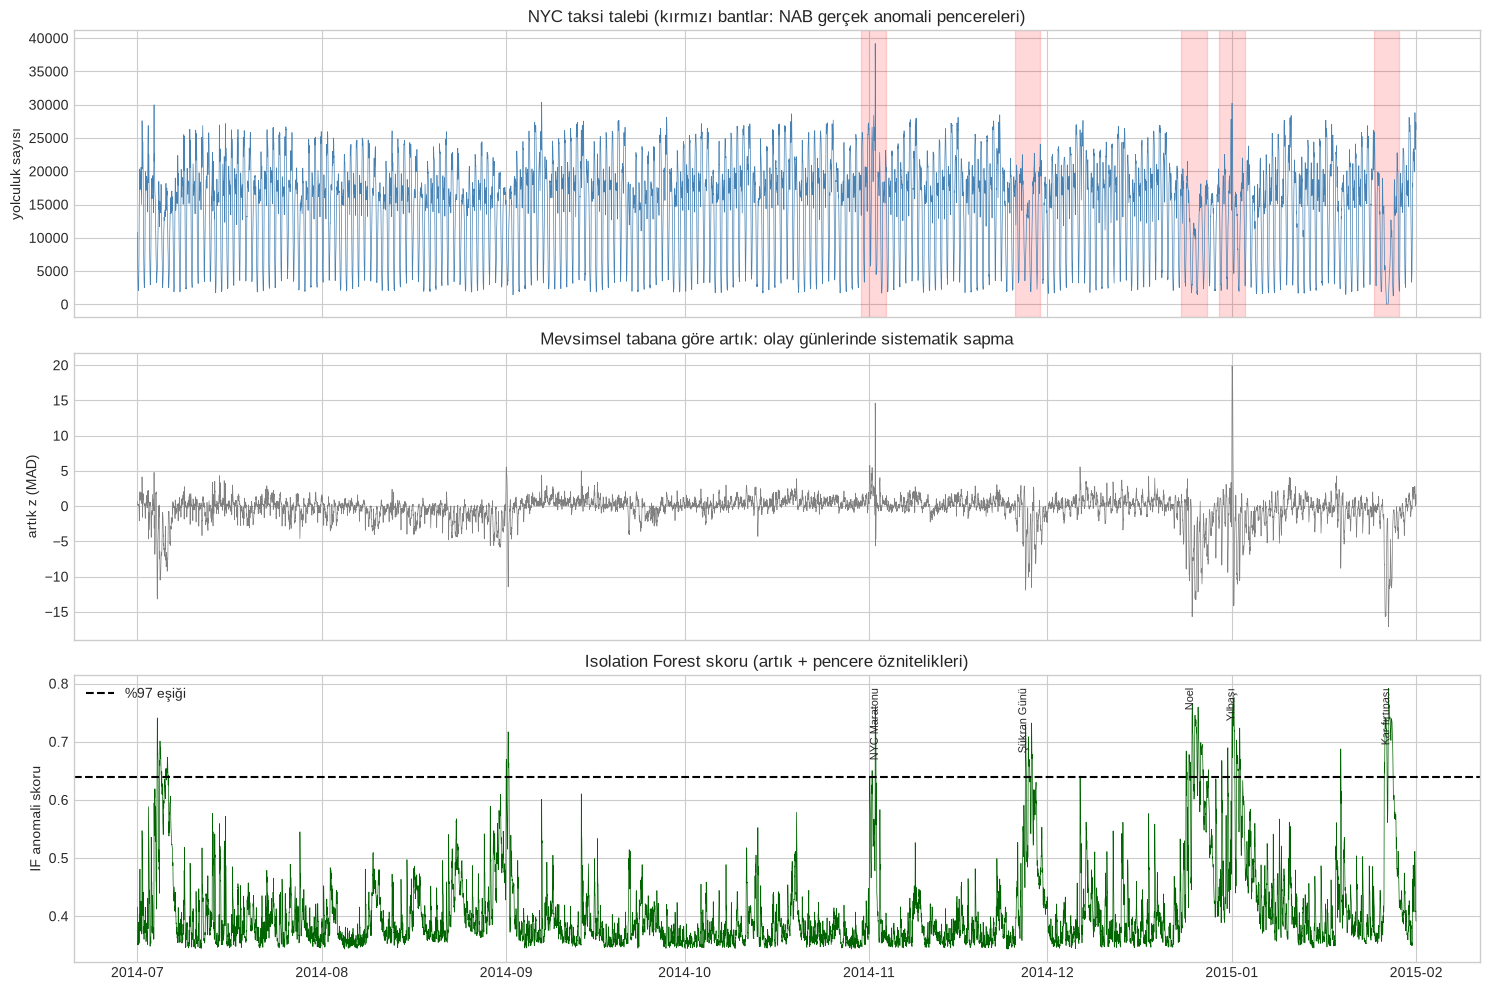

YORUM: Ham değerde (üst panel) olaylar mevsimsel dalgalanmanın içinde kaybolur; taban çizgisi çıkarıldığında (orta panel) olay günleri öne çıkar. Bağlam = tüm iş.


In [20]:
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
axes[0].plot(taxi.timestamp, taxi.value, lw=0.5, color='steelblue'); axes[0].set_ylabel('yolculuk sayısı')
for a, b in windows: axes[0].axvspan(pd.to_datetime(a), pd.to_datetime(b), color='red', alpha=0.15)
axes[0].set_title('NYC taksi talebi (kırmızı bantlar: NAB gerçek anomali pencereleri)')
axes[1].plot(taxi.timestamp, taxi.rz, lw=0.5, color='gray'); axes[1].set_ylabel('artık z (MAD)'); axes[1].set_title('Mevsimsel tabana göre artık: olay günlerinde sistematik sapma')
axes[2].plot(taxi.timestamp, taxi.if_score, lw=0.5, color='darkgreen'); axes[2].axhline(taxi.if_score.quantile(0.97), ls='--', color='k', label='%97 eşiği')
axes[2].set_ylabel('IF anomali skoru'); axes[2].legend(); axes[2].set_title('Isolation Forest skoru (artık + pencere öznitelikleri)')
for ev, d in events.items(): axes[2].annotate(ev, (pd.to_datetime(d), taxi.if_score.max()), fontsize=8, rotation=90, va='top', ha='center')
plt.tight_layout(); plt.show()
print('YORUM: Ham değerde (üst panel) olaylar mevsimsel dalgalanmanın içinde kaybolur; taban çizgisi çıkarıldığında (orta panel) olay günleri öne çıkar. Bağlam = tüm iş.')

## Adım 9 · Etiket Varsa Ne Kazanırız? Denetimli Model ve Maliyet-Duyarlı Eşik

**Ne yapıyoruz?** (1) Cardio'da etiketli anomali sayısı arttıkça **RandomForest** (denetimli) ortalama hassasiyetinin (AP) nasıl yükseldiğini ve denetimsiz yöntemlerin AP çizgisini
hangi etiket miktarında geçtiğini 5-katlı CV ile ölçüyoruz ("kaç etikete ihtiyacım var?" sorusu). (2) §7'deki iş-maliyeti perspektifiyle Isolation Forest skoru için
**maliyet matrisi**ne (kaçırılan anomali = 50, yanlış alarm = 1) göre eşik seçiyoruz ve `contamination` varsayımına dayalı eşikle kıyaslıyoruz (12 · Dengesiz Öğrenme ile aynı mantık).

,etiketli eğitim oranı,ort. etiketli anomali sayısı,RF AP (5-kat CV)
0,0.02,3.8,0.783
1,0.05,7.2,0.860
2,0.10,13.6,0.940
3,0.25,34.0,0.966
4,0.50,67.4,0.982
5,1.00,140.8,0.992


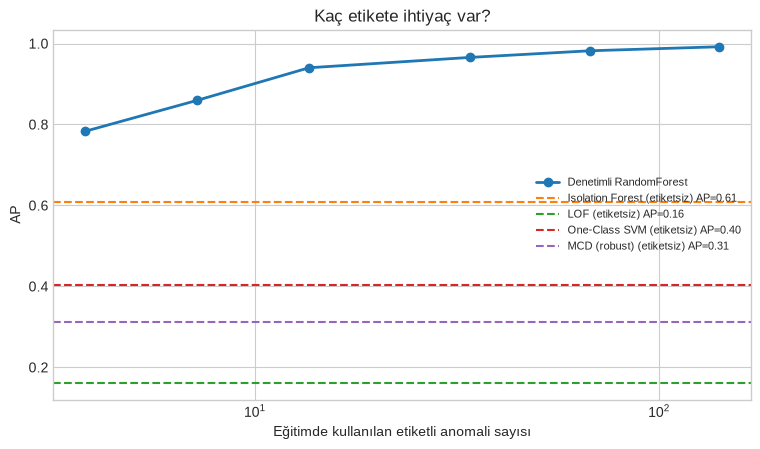

YORUM: Bu veri setinde denetimli RandomForest, ortalama yalnızca ~4 etiketli anomaliyle bile en iyi denetimsiz dedektörün AP'sini (0.61) geçiyor (RF AP = 0.78).
       Dikkat: Cardio'da anomali sınıfı özniteliklerle iyi ayrışıyor; her veri böyle değildir. Etiket yoksa denetimsiz başla, etiket biriktikçe denetimliye geç; yeni anomali TÜRLERİ için dedektörü ikinci katman olarak tut.


In [21]:
skf = StratifiedKFold(5, shuffle=True, random_state=0); fracs = [0.02, 0.05, 0.1, 0.25, 0.5, 1.0]
res = {f: [] for f in fracs}; n_lab = {f: [] for f in fracs}; rs = np.random.RandomState(0)
for tr, te in skf.split(X_c, y_c):
    for f in fracs:
        sub = rs.choice(tr, max(int(len(tr) * f), 20), replace=False)
        if y_c[sub].sum() < 2: sub = np.r_[sub, rs.choice(tr[y_c[tr] == 1], 3, replace=False)]
        rf = RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', random_state=0, n_jobs=2).fit(X_c[sub], y_c[sub])
        res[f].append(average_precision_score(y_c[te], rf.predict_proba(X_c[te])[:, 1])); n_lab[f].append(int(y_c[sub].sum()))
sup = pd.DataFrame({'etiketli eğitim oranı': fracs, 'ort. etiketli anomali sayısı': [np.mean(n_lab[f]) for f in fracs], 'RF AP (5-kat CV)': [np.mean(res[f]) for f in fracs]})
display(sup.round(3))
unsup_ap = {n: bench['Cardio'][0][n] for n in ['Isolation Forest', 'LOF', 'One-Class SVM', 'MCD (robust)']}
unsup_ap = {n: average_precision_score(y_c, s) for n, s in unsup_ap.items()}
fig, ax = plt.subplots(figsize=(9, 4.8)); ax.plot(sup['ort. etiketli anomali sayısı'], sup['RF AP (5-kat CV)'], 'o-', lw=2, label='Denetimli RandomForest')
for (n, v), col in zip(unsup_ap.items(), ['C1', 'C2', 'C3', 'C4']): ax.axhline(v, ls='--', color=col, label=f'{n} (etiketsiz) AP={v:.2f}')
ax.set_xscale('log'); ax.set_xlabel('Eğitimde kullanılan etiketli anomali sayısı'); ax.set_ylabel('AP'); ax.legend(fontsize=8); ax.set_title('Kaç etikete ihtiyaç var?'); plt.show()
best_unsup = max(unsup_ap.values()); first = sup[sup['RF AP (5-kat CV)'] > best_unsup].iloc[0]
print('YORUM: Bu veri setinde denetimli RandomForest, ortalama yalnızca ~%.0f etiketli anomaliyle bile en iyi denetimsiz dedektörün AP\'sini (%.2f) geçiyor (RF AP = %.2f).' % (first['ort. etiketli anomali sayısı'], best_unsup, first['RF AP (5-kat CV)']))
print('       Dikkat: Cardio\'da anomali sınıfı özniteliklerle iyi ayrışıyor; her veri böyle değildir. Etiket yoksa denetimsiz başla, etiket biriktikçe denetimliye geç; yeni anomali TÜRLERİ için dedektörü ikinci katman olarak tut.')

,Strateji,İşaretlenen kayıt,"Toplam maliyet (FN=50, FP=1)"
0,Hiç alarm yok,0,8800.0
1,contamination=0.05,91,6035.0
2,contamination=0.096,175,4283.0
3,contamination=0.2,366,1924.0
4,Maliyet-optimal eşik,641,516.0
5,Her kaydı işaretle,1831,1655.0


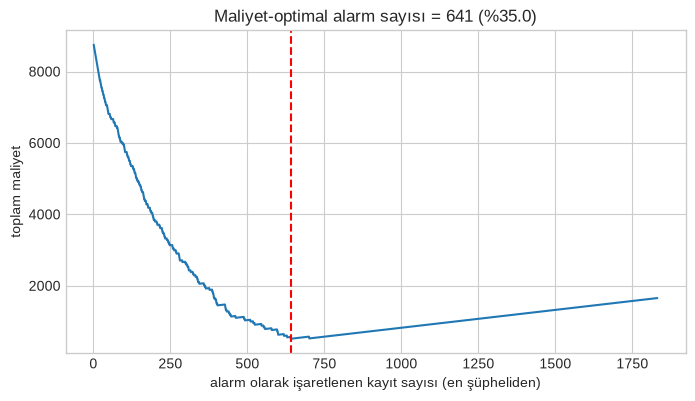

YORUM: Kaçırmak yanlış alarmdan 50 kat pahalıysa optimal eşik, "beklenen anomali oranı"ndan (%9.6) çok daha geniş bir alarm bandı seçiyor: eşik istatistik değil iş kararıdır.


In [22]:
# --- Maliyet-duyarlı eşik (IF skoru, Cardio) ---
C_FN, C_FP = 50.0, 1.0
order = np.argsort(s_if)[::-1]; ys = y_c[order]
tp = np.cumsum(ys); fp = np.cumsum(1 - ys); k = np.arange(1, len(ys) + 1)
cost = C_FN * (y_c.sum() - tp) + C_FP * fp                     # k kaydı alarm olarak işaretlersek toplam maliyet
k_best = int(np.argmin(cost)) + 1
rows = [('Hiç alarm yok', 0, C_FN * y_c.sum())]
rows += [(f'contamination={c}', int(len(y_c) * c), cost[int(len(y_c) * c) - 1]) for c in [0.05, 0.096, 0.2]]
rows += [('Maliyet-optimal eşik', k_best, cost[k_best - 1]), ('Her kaydı işaretle', len(y_c), C_FP * (len(y_c) - y_c.sum()))]
display(pd.DataFrame(rows, columns=['Strateji', 'İşaretlenen kayıt', f'Toplam maliyet (FN={C_FN:.0f}, FP={C_FP:.0f})']).round(0))
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.plot(k, cost); ax.axvline(k_best, ls='--', color='r'); ax.set_xlabel('alarm olarak işaretlenen kayıt sayısı (en şüpheliden)'); ax.set_ylabel('toplam maliyet')
ax.set_title(f'Maliyet-optimal alarm sayısı = {k_best} (%{100 * k_best / len(y_c):.1f})'); plt.show()
print('YORUM: Kaçırmak yanlış alarmdan 50 kat pahalıysa optimal eşik, "beklenen anomali oranı"ndan (%9.6) çok daha geniş bir alarm bandı seçiyor: eşik istatistik değil iş kararıdır.')

# 📊 R Uygulaması

R'da anomali tespiti için olgun paketler var: **`isotree`** (Isolation Forest'ın hızlı C++ uygulaması + **Extended Isolation Forest**: eksene paralel olmayan bölmeler),
**`dbscan::lof`** (LOF) ve **`robustbase::covMcd`** (MCD'nin referans uygulaması; robust istatistik R'ın güçlü olduğu bir alan). Proje kararı gereği
(bkz. [[notebook_style_convention]]) R bölümünü kısa tutuyoruz: 1 hücre `isotree` + `lof` (Cardio), 1 hücre `robustbase::covMcd` (Cardio, klasik vs robust Mahalanobis).

In [ ]:
%load_ext rpy2.ipython
cardio_for_r = cardio.copy()

In [ ]:
%%R -i cardio_for_r -w 900 -h 400
# install.packages(c("isotree", "dbscan", "pROC"))  # ilk çalıştırmada gerekir
library(isotree); library(dbscan); library(pROC)
y <- cardio_for_r$label; X <- as.matrix(cardio_for_r[, setdiff(names(cardio_for_r), "label")])
set.seed(42)
iso <- isolation.forest(X, ntrees = 300, sample_size = 256, ndim = 1, nthreads = 2)        # klasik Isolation Forest
ext <- isolation.forest(X, ntrees = 300, sample_size = 256, ndim = 2, nthreads = 2)        # Extended IF: 2 öznitelikli eğik kesmeler
s_iso <- predict(iso, X); s_ext <- predict(ext, X)
s_lof <- lof(scale(X), minPts = 36)                                                       # dbscan::lof: minPts = k + 1
cat("AUC — IsolationForest:", round(auc(roc(y, s_iso, quiet = TRUE)), 3),
    "| ExtendedIF:", round(auc(roc(y, s_ext, quiet = TRUE)), 3),
    "| LOF (k=35):", round(auc(roc(y, s_lof, quiet = TRUE)), 3), "\n")
boxplot(s_iso ~ y, names = c("normal", "anomali"), main = "R isotree: anomali skoru (Cardio)", ylab = "skor")

In [ ]:
%%R -i cardio_for_r -w 900 -h 400
library(robustbase); library(pROC)
y <- cardio_for_r$label; X <- as.matrix(cardio_for_r[, setdiff(names(cardio_for_r), "label")])
cl <- colMeans(X); Sc <- cov(X)
d_cls <- mahalanobis(X, cl, Sc)                       # klasik
mcd <- covMcd(X)                                      # FastMCD
d_mcd <- mahalanobis(X, mcd$center, mcd$cov)          # robust
cat("AUC — klasik Mahalanobis:", round(auc(roc(y, d_cls, quiet = TRUE)), 3), "| MCD Mahalanobis:", round(auc(roc(y, d_mcd, quiet = TRUE)), 3), "\n")
cat("MCD'nin temiz çekirdek (kullanılan) gözlem sayısı:", length(mcd$best), "/", nrow(X), "\n")
plot(d_cls, d_mcd, col = y + 1, pch = 19, cex = .5, log = "xy", xlab = "klasik Mahalanobis²", ylab = "MCD Mahalanobis²", main = "Klasik vs robust uzaklık (kırmızı: anomali)")
abline(0, 1, lty = 2)

# 🗄️ SQL Uygulaması (DuckDB)

Anomali tespiti üretimde çoğu zaman **veri ambarında, SQL ile** çalışır (günlük batch izleme, metrik alarmları). Bu serinin tekrar eden desenini (bkz. [[classical_ml_progress]]) iki noktada uyguluyoruz;
proje kararı gereği (bkz. [[notebook_style_convention]]) her biri tek hücre:

1. **Mahalanobis skoru SQL'de:** $d_M^2=(\mathbf{x}-\boldsymbol{\mu})^\top\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu})$ — kayıtlar uzun biçimde (id, öznitelik, değer) ve $\boldsymbol{\Sigma}^{-1}$ bir tablo olarak;
   iki kendine-birleştirme (`JOIN`) + `SUM` ile Cardio'nun 1.831 kaydının skorunu hesaplıyoruz ve `sklearn` ile karşılaştırıyoruz.
2. **Zaman serisi anomali öznitelikleri pencere fonksiyonlarıyla:** NYC taksi için (haftanın günü, saat dilimi) bazlı **medyan taban çizgisi** (`MEDIAN() OVER (PARTITION BY ...)`), MAD ile ölçekleme
   ve **kayan pencere** ortalaması (`AVG() OVER (ROWS BETWEEN ...)`) — Adım 8'in özniteliklerini SQL'de yeniden üretiyor ve günlük alarm sıralaması çıkarıyoruz.

In [26]:
import duckdb
con = duckdb.connect()

# --- SQL-1: Mahalanobis² (Cardio, 21 öznitelik) ---
n_, p_ = X_c.shape
mu = X_c.mean(0); P = np.linalg.inv(np.cov(X_c.T, bias=True))                  # EmpiricalCovariance = bias=True kovaryans
long = pd.DataFrame({'id': np.repeat(np.arange(n_), p_), 'dim': np.tile(np.arange(p_), n_), 'xc': (X_c - mu).ravel()})
prec = pd.DataFrame({'i': np.repeat(np.arange(p_), p_), 'j': np.tile(np.arange(p_), p_), 'p': P.ravel()})
con.register('long', long); con.register('prec', prec)
maha_sql = con.execute("""
    SELECT a.id, SUM(a.xc * pr.p * b.xc) AS d2
    FROM long a JOIN prec pr ON a.dim = pr.i JOIN long b ON b.id = a.id AND b.dim = pr.j
    GROUP BY a.id ORDER BY a.id
""").df()
print('SQL Mahalanobis² vs sklearn EmpiricalCovariance.mahalanobis — maks. fark: %.2e' % np.abs(maha_sql['d2'].to_numpy() - score_maha).max())
print('SQL skoruyla ROC-AUC: %.3f (Adım 1 ile aynı)' % roc_auc_score(y_c, maha_sql['d2']))
top = maha_sql.sort_values('d2', ascending=False).head(5); top['gerçek_anomali'] = y_c[top['id'].to_numpy()]
print('\nEn şüpheli 5 kayıt (SQL):'); display(top.round(1).reset_index(drop=True))
print('YORUM: Parametre tablosu (μ, Σ⁻¹) + iki JOIN: anomali skoru bir sorguya indirgendi; 1.831×21×21 ≈ 807 bin çarpım veritabanında.')

SQL Mahalanobis² vs sklearn EmpiricalCovariance.mahalanobis — maks. fark: 5.40e-13
SQL skoruyla ROC-AUC: 0.896 (Adım 1 ile aynı)

En şüpheli 5 kayıt (SQL):


,id,d2,gerçek_anomali
0,1781,412.6,1
1,1779,304.1,1
2,1741,293.9,1
3,1780,292.5,1
4,1778,235.0,1


YORUM: Parametre tablosu (μ, Σ⁻¹) + iki JOIN: anomali skoru bir sorguya indirgendi; 1.831×21×21 ≈ 807 bin çarpım veritabanında.


In [27]:
# --- SQL-2: NYC taksi — pencere fonksiyonlarıyla taban çizgisi, MAD ve kayan ortalama ---
tx = taxi[['timestamp', 'value']].rename(columns={'timestamp': 'ts'}); con.register('tx', tx)
feat_sql = con.execute("""
WITH f AS (
    SELECT ts, value, DAYOFWEEK(ts) AS dow_sql, HOUR(ts) * 2 + MINUTE(ts) // 30 AS slot,
           value - MEDIAN(value) OVER (PARTITION BY ((DAYOFWEEK(ts) + 6) % 7), HOUR(ts) * 2 + MINUTE(ts) // 30) AS resid
    FROM tx
), m AS (SELECT MEDIAN(resid) AS med FROM f),
mad AS (SELECT MEDIAN(ABS(resid - (SELECT med FROM m))) * 1.4826 AS mad FROM f)
SELECT ts, resid / (SELECT mad FROM mad) AS rz,
       AVG(resid / (SELECT mad FROM mad)) OVER (ORDER BY ts ROWS BETWEEN 5 PRECEDING AND CURRENT ROW) AS rz_m6,
       AVG(resid / (SELECT mad FROM mad)) OVER (ORDER BY ts ROWS BETWEEN 47 PRECEDING AND CURRENT ROW) AS rz_m48
FROM f ORDER BY ts
""").df()
print('SQL ile üretilen öznitelik tablosu:', feat_sql.shape)
for c in ['rz', 'rz_m6', 'rz_m48']:
    print(f'  {c}: pandas ile maks. mutlak fark = {np.abs(feat_sql[c].to_numpy() - taxi[c].to_numpy()).max():.2e}')

# günlük alarm sıralaması: günün ortalama |kayan artık|'ı (SQL)
con.register('feat_sql', feat_sql)
daily_sql = con.execute("""
    SELECT CAST(ts AS DATE) AS day, AVG(ABS(rz_m6)) AS mean_abs_rz_m6, MAX(ABS(rz_m48)) AS max_abs_rz_m48
    FROM feat_sql GROUP BY 1 ORDER BY mean_abs_rz_m6 DESC LIMIT 8
""").df()
display(daily_sql.round({'mean_abs_rz_m6': 3, 'max_abs_rz_m48': 3}))
print('YORUM: Kayan pencere + mevsimsel medyan SQL\'de birer pencere fonksiyonu; listenin başında NAB olay günlerinden Ocak 27, Ocak 1, Aralık 25 ve Kasım 27 görünüyor; ayrıca 4 Temmuz gibi takvimde bilinen tatiller de yakalanıyor (Kasım 2 maratonu bu iki ölçüde ilk sekize girmiyor).')

SQL ile üretilen öznitelik tablosu: (10320, 4)
  rz: pandas ile maks. mutlak fark = 0.00e+00
  rz_m6: pandas ile maks. mutlak fark = 5.33e-15
  rz_m48: pandas ile maks. mutlak fark = 3.55e-15


,day,mean_abs_rz_m6,max_abs_rz_m48
0,2015-01-27,9.212,10.472
1,2015-01-01,7.534,2.533
2,2014-12-25,7.042,7.196
3,2014-12-26,5.873,8.298
4,2014-07-05,5.497,6.029
5,2014-12-27,5.058,6.154
6,2014-07-04,4.948,4.723
7,2014-11-27,4.913,4.471


YORUM: Kayan pencere + mevsimsel medyan SQL'de birer pencere fonksiyonu; listenin başında NAB olay günlerinden Ocak 27, Ocak 1, Aralık 25 ve Kasım 27 görünüyor; ayrıca 4 Temmuz gibi takvimde bilinen tatiller de yakalanıyor (Kasım 2 maratonu bu iki ölçüde ilk sekize girmiyor).


## ✏️ Egzersizler

Hepsi bu notebook'ta tanımlı değişkenlerle ve **hazır modellerle** çözülebilir (sıfırdan kod yazmak gerekmiyor). Her egzersizin kod hücresinde, **nasıl yapılacağını adım adım
gösteren `# TODO` yönlendirmeleri** var — çözüm yok; TODO'ları kod satırlarına çevirmek senin işin. Her egzersizde kodun altına 1-2 cümlelik yorumunu da yaz.

**E1.** `Letter` verisinde (`X_l`, `y_l`) `IsolationForest`'ı `max_samples ∈ {64, 256, 1600}` için (her biri 3 farklı `random_state` ile) çalıştır ve ROC-AUC ortalama/std değerlerini tablo yap.
Alt örneklem boyutu sonucu nasıl etkiliyor? Neden `max_samples` çok büyük olduğunda (tüm veri) maskeleme/batma riski artıyor olabilir? (§3.2, adım 1)

In [28]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: İç içe döngü: `for ms in [64, 256, 1600]: for seed in [0, 1, 2]:`.
# TODO 2: `m = IsolationForest(n_estimators=300, max_samples=ms, random_state=seed).fit(X_l)`.
# TODO 3: Skor işaretini çevir: `s = -m.score_samples(X_l)` (yüksek = daha anormal); `roc_auc_score(y_l,
#         s)` ile AUC hesapla.
# TODO 4: Sonuçları `(ms, seed, auc)` satırları olarak bir listeye ekle;
#         `pd.DataFrame(...).groupby('ms')['auc'].agg(['mean', 'std'])` ile özetle.
# TODO 5: Yorum: hangi `max_samples` en iyi? Tohumlar arası std, seçimin sağlamlığı hakkında ne söylüyor?

**E2.** `Letter` verisinde **yarı-denetimli LOF** kur: normal kayıtların %70'i ile `LocalOutlierFactor(novelty=True)` eğit, kalan %30 normal + tüm anomalilerle test et. `k ∈ {5, 20, 50}` için
AUC ve AP hesapla. Denetimsiz (tüm veriye `fit`) LOF sonucuyla (Adım 3'teki tablo) karşılaştır — normal-only eğitim bir avantaj sağlıyor mu?

In [29]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: `idx_n = np.where(y_l == 0)[0]; idx_a = np.where(y_l == 1)[0]`; `tr, te_n =
#         train_test_split(idx_n, test_size=0.3, random_state=42)`.
# TODO 2: Ölçekleyiciyi SADECE eğitimden öğren: `sc = StandardScaler().fit(X_l[tr])`; test: `te =
#         np.r_[te_n, idx_a]`; `y_te = y_l[te]`.
# TODO 3: Her `k` için `lof = LocalOutlierFactor(n_neighbors=k, novelty=True).fit(sc.transform(X_l[tr]))`.
# TODO 4: Skor: `s = -lof.score_samples(sc.transform(X_l[te]))` (yüksek = anormal).
# TODO 5: `roc_auc_score(y_te, s)` ve `average_precision_score(y_te, s)`; sonuçları k'ya göre tabloya koy
#         ve `ktab` (denetimsiz LOF) ile kıyasla.

**E3.** Cardio'da ölçekli veriyle (`Xc_s`) One-Class SVM'i `ν ∈ {0.01, 0.05, 0.1, 0.2, 0.4}` için çalıştır. Her biri için (a) **kesin dışarıda kalan eğitim oranını** (`decision_function < -1e-3`; `predict==-1` sınırdaki sayısal toleransı da sayar, bkz. Adım 4),
(b) destek vektörü oranını, (c) ROC-AUC'yi hesapla. §5.2'deki "$\\nu$ özelliği" (dışarıda kalan ≤ ν ≤ destek vektörü oranı) burada geçerli mi?

In [30]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Döngü: `for nu in [0.01, 0.05, 0.1, 0.2, 0.4]:` ve `m = OneClassSVM(kernel='rbf', gamma='scale',
#         nu=nu).fit(Xc_s)`.
# TODO 2: (a) `outlier_frac = (m.decision_function(Xc_s) < -1e-3).mean()` (kesin dışarıda); isteğe bağlı
#         karşılaştırma: `(m.predict(Xc_s) == -1).mean()`. (b) `sv_frac = len(m.support_) / len(Xc_s)`.
# TODO 3: (c) `auc = roc_auc_score(y_c, -m.score_samples(Xc_s))` (yüksek = anormal olacak şekilde işaret
#         çevir).
# TODO 4: Üç büyüklüğü bir DataFrame'e topla; `outlier_frac <= nu <= sv_frac` eşitsizliğini her satır için
#         kontrol eden bir boolean sütun ekle.
# TODO 5: Yorum: ν'yü artırmak AUC'yi iyileştiriyor mu? Eşiği (ν) ve sıralamayı (AUC) ayrı ayrı yorumla
#         (§7'deki contamination tuzağı).

**E4.** Cardio'da `MinCovDet`'in `support_fraction` parametresini `{0.6, 0.75, 0.9, None}` (None = varsayılan) için çalıştır; her biri için ROC-AUC ve fit süresini yaz.
Klasik `EmpiricalCovariance` AUC'si (`score_maha`) ile kıyasla. Düşük `support_fraction` değerlerinde sklearn'ün verdiği sayısal uyarıları `warnings.catch_warnings(record=True)` ile sayıp tabloya ekle (`fit_mcd` yardımcı fonksiyonuna bak). Robust olmanın bedeli (süre) ve getirisi (AUC) nedir?

In [31]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Döngü: `for sf in [0.6, 0.75, 0.9, None]:`; `t0 = time.time()`; `m =
#         MinCovDet(support_fraction=sf, random_state=0).fit(X_c)`; `dt = time.time() - t0`.
# TODO 2: Skor: `s = m.mahalanobis(X_c)`; `roc_auc_score(y_c, s)` ve `average_precision_score(y_c, s)`.
# TODO 3: Sonuçları `(sf, AUC, AP, süre)` tablosuna ekle; son satır olarak klasik `EmpiricalCovariance`
#         sonucunu (Adım 1'deki `score_maha`) ekle.
# TODO 4: Düşük `support_fraction` daha robust ama daha az veriyle tahmin demektir (verimlilik kaybı):
#         tablodan bu değiş-tokuşu yorumla.

**E5.** `bench['Letter']` içinde hazır duran skorlarla (IF, LOF, One-Class SVM, MCD) **tüm 2'li ve 3'lü rank-averaging kombinasyonlarını** dene (`itertools.combinations`).
Her kombinasyonun Letter ROC-AUC'sini hesapla; en iyi kombinasyon, en iyi tekil yönteme göre ne kadar kazandırıyor? Topluluk her zaman daha iyi mi?

In [32]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: `sc_l, _, y_l_ = bench['Letter']`; yöntem adları: `['Isolation Forest', 'LOF', 'One-Class SVM',
#         'MCD (robust)']`.
# TODO 2: Her skoru `rank01(sc_l[ad])` ile 0-1 sıra yüzdesine çevir (Adım 6'daki fonksiyon).
# TODO 3: `for r in [2, 3]: for combo in itertools.combinations(adlar, r):` ile kombinasyonları dolaş
#         (`import itertools`).
# TODO 4: Skor = seçilen yöntemlerin sıra yüzdelerinin ortalaması: `np.mean([rank01(sc_l[a]) for a in
#         combo], axis=0)`; `roc_auc_score(y_l_, skor)`.
# TODO 5: Sonuçları AUC'ye göre sırala; en iyi tekil AUC'yi (`piv['Letter'].max()`) referans al; farkı ve
#         sonucu yorumla.

**E6.** Adım 8'in boru hattını **makine sıcaklığı** verisine (`data/machine_temp.csv`; NAB `machine_temperature_system_failure`: endüstriyel makine sıcaklık sensörü, 5 dakikalık, 4 gerçek arıza penceresi) uygula.
Bu seride haftalık mevsimsellik yok; bağlamı bir **kayan medyan taban çizgisi** ile (örn. 288 örnek = 1 gün) kur. Isolation Forest'ın nokta düzeyi AUC'sini ve her arıza penceresinin IF skorunun
en yüksek %5'ine girip girmediğini raporla.

In [33]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Veriyi oku: `mt = pd.read_csv('data/machine_temp.csv', parse_dates=['timestamp'])`; pencereler:
#         `json.load(open('data/nab_windows.json'))['realKnownCause/machine_temperature_system_failure.csv
#         ']`.
# TODO 2: Etiket: pencerelerin içine düşen noktalara 1 ver (Adım 8'deki döngünün aynısı).
# TODO 3: Taban çizgisi: `base = mt['value'].rolling(288, center=True, min_periods=1).median()`; `resid =
#         mt['value'] - base`; MAD ile ölçekle (`rz`).
# TODO 4: Öznitelikler: `rz`, `rz.rolling(12).mean()`, `rz.rolling(12).std()` (NaN'leri `fillna(0)` ile
#         doldur).
# TODO 5: `IsolationForest(n_estimators=300, random_state=42)` ile skorla (`-score_samples`);
#         `roc_auc_score(label, skor)`.
# TODO 6: Olay düzeyi: her pencere için `skor` en yüksek %5 eşiğini (`np.quantile(skor, 0.95)`) aşan en az
#         bir nokta var mı? Kaç pencere yakalandı?

## 📚 Kaynaklar

| Kaynak | Bölüm | Notlar |
|---|---|---|
| [Liu, Ting, Zhou (2008) — "Isolation Forest", *IEEE ICDM*](https://doi.org/10.1109/ICDM.2008.17) | Isolation Forest | Orijinal makale ($c(n)$, skor formülü) |
| [Liu, Ting, Zhou (2012) — "Isolation-Based Anomaly Detection", *ACM TKDD*](https://doi.org/10.1145/2133360.2133363) | Isolation Forest | Genişletilmiş dergi sürümü (alt örnekleme analizi) |
| [Hariri, Kind, Brunner (2021) — "Extended Isolation Forest", *IEEE TKDE*](https://doi.org/10.1109/TKDE.2019.2947676) | Extended IF | Eksene paralel olmayan bölmeler (R `isotree`'de `ndim>1`) |
| [Breunig, Kriegel, Ng, Sander (2000) — "LOF: Identifying Density-Based Local Outliers", *ACM SIGMOD*](https://doi.org/10.1145/335191.335388) | LOF | Orijinal makale (lrd, reach-dist, LOF) |
| [Schölkopf ve ark. (2001) — "Estimating the Support of a High-Dimensional Distribution", *Neural Computation*](https://doi.org/10.1162/089976601750264965) | One-Class SVM | $\nu$ özelliğinin türetimi |
| [Rousseeuw & Van Driessen (1999) — "A Fast Algorithm for the Minimum Covariance Determinant Estimator", *Technometrics*](https://doi.org/10.1080/00401706.1999.10485670) | MCD / Elliptic Envelope | FastMCD algoritması |
| [Chandola, Banerjee, Kumar (2009) — "Anomaly Detection: A Survey", *ACM Computing Surveys*](https://doi.org/10.1145/1541880.1541882) | Genel çerçeve | Nokta/bağlamsal/kolektif ayrımı |
| [Campos ve ark. (2016) — "On the evaluation of unsupervised outlier detection", *Data Mining and Knowledge Discovery*](https://doi.org/10.1007/s10618-015-0444-8) | Değerlendirme | Benchmark protokolü ve ODDS benzeri veri setlerinin kullanımı |
| [Aggarwal — *Outlier Analysis* (Springer, 2. baskı)](https://link.springer.com/book/10.1007/978-3-319-47578-3) | Kitap | Anomali tespitinin kapsamlı ders kitabı |
| [scikit-learn — Novelty and Outlier Detection](https://scikit-learn.org/stable/modules/outlier_detection.html) | Tüm yöntemler | `novelty` vs outlier ayrımı, yöntem karşılaştırma şekilleri |
| [Zhao, Nasrullah, Li (2019) — "PyOD: A Python Toolbox for Scalable Outlier Detection", *JMLR*](https://jmlr.org/papers/v20/19-011.html) · [GitHub](https://github.com/yzhao062/pyod) | Araç kutusu | 40+ dedektör ve ODDS verileri (`examples/data`) |
| [Rayana (2016) — ODDS: Outlier Detection DataSets](http://odds.cs.stonybrook.edu/) | Veri: Cardio, Letter, Arrhythmia | Benchmark veri seti deposu; veriler `pyod` GitHub reposundan alındı |
| [UCI — Cardiotocography](https://archive.ics.uci.edu/dataset/193/cardiotocography) · [UCI — Arrhythmia](https://archive.ics.uci.edu/dataset/5/arrhythmia) · [UCI — Letter Recognition](https://archive.ics.uci.edu/dataset/59/letter+recognition) | Veri kaynakları | ODDS veri setlerinin orijinal kaynakları |
| [Lavin & Ahmad (2015) — "Evaluating Real-time Anomaly Detection Algorithms: the Numenta Anomaly Benchmark"](https://arxiv.org/abs/1510.03336) · [GitHub: numenta/NAB](https://github.com/numenta/NAB) | Zaman serisi; Veri: NYC Taxi, Machine Temp | Etiket pencereleri ve olay-düzeyi skorlama |
| [`isotree`](https://cran.r-project.org/package=isotree) · [`dbscan`](https://cran.r-project.org/package=dbscan) · [`robustbase`](https://cran.r-project.org/package=robustbase) | R bölümü | CRAN sayfaları |